# M6 EnComs Metagenomics - Neor 1 population genomic variability analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.stats import ttest_ind
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import linregress
import sys

mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
#Import data for the conditions of each sample to use later
metadata_path = './data/EnCom_all_sample_info_misc_data_layer.txt'
sample_info_df = pd.read_csv(metadata_path,sep='\t')

#Create a sample order list identical to that used for the stacked bar chart for consistency
sample_order = sample_info_df.replace({'NLDM':'1 NLDM','glucose':'2 glucose','acetate':'3 acetate','citrate':'4 citrate','lactate':'5 lactate','pyruvate':'6 pyruvate','no C':'7 no C'}).sort_values(['Media','Timepoint','C source','pH','[NO3]']).replace({'1 NLDM':'NLDM','2 glucose':'glucose','3 acetate':'acetate','4 citrate':'citrate','5 lactate':'lactate','6 pyruvate':'pyruvate','7 no C':'no C'})['samples'].to_list() #sort by these variables in order for optimal grouping and create list to use to order columns for abund df
sample_info_df = sample_info_df.replace({'NLDM':'1 NLDM','glucose':'2 glucose','acetate':'3 acetate','citrate':'4 citrate','lactate':'5 lactate','pyruvate':'6 pyruvate','no C':'7 no C'}).sort_values(['Media','Timepoint','C source','pH','[NO3]']).replace({'1 NLDM':'NLDM','2 glucose':'glucose','3 acetate':'acetate','4 citrate':'citrate','5 lactate':'lactate','6 pyruvate':'pyruvate','7 no C':'no C'}) #Go ahead and save this as the structure of the sample_info so it's the same later

#add a column to sample_info_df to give the C sources a numerical ID so it can be plotted as a heatmap for the heatmap figure
c_id_dict = {'no C': 0,
 'pyruvate': 1,
 'lactate': 2,
 'citrate': 3,
 'acetate': 4,
 'glucose': 5,
 'NLDM': 6}

#Also need a cmap list to match the colors to the C sources based on this numerical order
c_colors = ['xkcd:grey','xkcd:crimson','xkcd:beige','xkcd:peach','xkcd:turquoise','xkcd:olive','xkcd:light brown']

sample_info_df['C_ID'] = sample_info_df['C source'].map(c_id_dict)
sample_info_df

,samples,Timepoint,Media,pH,C source,[NO3],C_ID
0,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0,6
7,NLDM_T1_A8,T1,NLDM,4.5,NLDM,0,6
8,NLDM_T1_B1,T1,NLDM,4.5,NLDM,0,6
15,NLDM_T1_B8,T1,NLDM,4.5,NLDM,0,6
1,NLDM_T1_A2,T1,NLDM,4.5,NLDM,5,6
...,...,...,...,...,...,...,...
258,SGW_T3_F7,T3,SGW,7.0,no C,10,0
246,SGW_T3_E7,T3,SGW,7.0,no C,15,0
234,SGW_T3_D7,T3,SGW,7.0,no C,20,0
222,SGW_T3_C7,T3,SGW,7.0,no C,30,0


In [3]:
#import the variability data. Beware, it's a 7.7 GB file and might take a few minutes to spin up.
#WARNING: because this file is so large, I can't add it to the github data folder. 
#You can generate this file and then run the notebook with it using the command:
#`anvi-gen-variability-profile -c CONTIGS/EnCom_all_contigs.db -p PROFILE/PROFILE.db -C manual_bins -b Bin_1 --engine CDN --include-site-pnps --compute-gene-coverage-stats -o Bin_1_cdn_pnps.txt`
bin_1_var_df = pd.read_csv('../ext_data/Bin_1_cdn_pnps.txt',sep='\t')
bin_1_var_df

,entry_id,unique_pos_identifier,sample_id,corresponding_gene_call,codon_order_in_gene,codon_number,gene_length,gene_coverage,non_outlier_gene_coverage,non_outlier_gene_coverage_std,...,nN_consensus,nS_consensus,pN_reference,pS_reference,nN_reference,nS_reference,pN_popular_consensus,pS_popular_consensus,nN_popular_consensus,nS_popular_consensus
0,2090333,547094,NLDM_T1_C8,19547,2,3,1203,182.843724,182.913405,20.650798,...,2.0,1.0,0.021127,0.014085,2.0,1.0,0.021127,0.014085,2.0,1.0
1,2368644,547094,NLDM_T1_D3,19547,2,3,1203,58.720698,60.844689,5.128697,...,2.0,1.0,0.032609,0.000000,2.0,1.0,0.032609,0.000000,2.0,1.0
2,2533374,547094,NLDM_T1_D4,19547,2,3,1203,195.804655,193.893953,17.919387,...,2.0,1.0,0.022152,0.063291,2.0,1.0,0.022152,0.063291,2.0,1.0
3,3400599,547094,NLDM_T1_E1,19547,2,3,1203,53.744805,55.204276,2.135233,...,2.0,1.0,0.022727,0.000000,2.0,1.0,0.022727,0.000000,2.0,1.0
4,4203919,547094,NLDM_T1_E5,19547,2,3,1203,107.372402,107.224456,10.939680,...,2.0,1.0,0.017442,0.034884,2.0,1.0,0.017442,0.034884,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15444347,9700450,672088,NLDM_T2_E5,141023,266,267,801,110.980025,111.516129,8.084677,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0
15444348,10602198,672088,NLDM_T2_E8,141023,266,267,801,103.369538,104.204819,4.312727,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0
15444349,12535366,672088,SGW_T1_D4,141023,266,267,801,73.563046,72.323651,5.539780,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0
15444350,13225686,672088,SGW_T1_F3,141023,266,267,801,90.232210,91.380507,7.415078,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0


In [4]:
#Let's filter out genes with coverage less than 10 and with a departure from consensus less than 0.1 (10%)
bin_1_var_df = bin_1_var_df[bin_1_var_df['gene_coverage'] >= 10]
bin_1_var_df = bin_1_var_df[bin_1_var_df['departure_from_consensus'] >= 0.10]
bin_1_var_df

,entry_id,unique_pos_identifier,sample_id,corresponding_gene_call,codon_order_in_gene,codon_number,gene_length,gene_coverage,non_outlier_gene_coverage,non_outlier_gene_coverage_std,...,nN_consensus,nS_consensus,pN_reference,pS_reference,nN_reference,nS_reference,pN_popular_consensus,pS_popular_consensus,nN_popular_consensus,nS_popular_consensus
2,2533374,547094,NLDM_T1_D4,19547,2,3,1203,195.804655,193.893953,17.919387,...,2.0,1.0,0.022152,0.063291,2.0,1.0,0.022152,0.063291,2.0,1.0
4,4203919,547094,NLDM_T1_E5,19547,2,3,1203,107.372402,107.224456,10.939680,...,2.0,1.0,0.017442,0.034884,2.0,1.0,0.017442,0.034884,2.0,1.0
6,5640497,547094,NLDM_T2_C2,19547,2,3,1203,54.139651,54.798913,3.083288,...,2.0,1.0,0.043478,0.043478,2.0,1.0,0.043478,0.043478,2.0,1.0
9,9144081,547094,NLDM_T2_E4,19547,2,3,1203,69.097257,69.097257,8.790138,...,2.0,1.0,0.044643,0.035714,2.0,1.0,0.044643,0.035714,2.0,1.0
13,13003930,547094,SGW_T1_F3,19547,2,3,1203,149.663342,152.355901,13.316355,...,2.0,1.0,0.042373,0.025424,2.0,1.0,0.042373,0.025424,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15444338,1439211,414201,NLDM_T1_C3,141023,265,266,801,68.484395,67.688742,1.048085,...,2.0,1.0,0.050000,0.050000,2.0,1.0,0.050000,0.050000,2.0,1.0
15444339,2086008,414201,NLDM_T1_C7,141023,265,266,801,69.515605,71.969156,3.021141,...,2.0,1.0,0.034483,0.017241,2.0,1.0,0.034483,0.017241,2.0,1.0
15444342,5326438,672088,NLDM_T1_F6,141023,266,267,801,20.716604,20.621039,3.286430,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0
15444343,6434165,672088,NLDM_T2_C4,141023,266,267,801,46.632959,46.632959,3.134140,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0


In [5]:
#Calculate pN/pS from the pN and pS values
#This is pN/pS for each codon, but needs to be calculated as a weighted average for per gene calculations. We'll import that data separately below
bin_1_var_df['pN/pS'] = bin_1_var_df['pN_consensus'].div(bin_1_var_df['pS_consensus'])
bin_1_var_df

,entry_id,unique_pos_identifier,sample_id,corresponding_gene_call,codon_order_in_gene,codon_number,gene_length,gene_coverage,non_outlier_gene_coverage,non_outlier_gene_coverage_std,...,nS_consensus,pN_reference,pS_reference,nN_reference,nS_reference,pN_popular_consensus,pS_popular_consensus,nN_popular_consensus,nS_popular_consensus,pN/pS
2,2533374,547094,NLDM_T1_D4,19547,2,3,1203,195.804655,193.893953,17.919387,...,1.0,0.022152,0.063291,2.0,1.0,0.022152,0.063291,2.0,1.0,0.350000
4,4203919,547094,NLDM_T1_E5,19547,2,3,1203,107.372402,107.224456,10.939680,...,1.0,0.017442,0.034884,2.0,1.0,0.017442,0.034884,2.0,1.0,0.500000
6,5640497,547094,NLDM_T2_C2,19547,2,3,1203,54.139651,54.798913,3.083288,...,1.0,0.043478,0.043478,2.0,1.0,0.043478,0.043478,2.0,1.0,1.000000
9,9144081,547094,NLDM_T2_E4,19547,2,3,1203,69.097257,69.097257,8.790138,...,1.0,0.044643,0.035714,2.0,1.0,0.044643,0.035714,2.0,1.0,1.250000
13,13003930,547094,SGW_T1_F3,19547,2,3,1203,149.663342,152.355901,13.316355,...,1.0,0.042373,0.025424,2.0,1.0,0.042373,0.025424,2.0,1.0,1.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15444338,1439211,414201,NLDM_T1_C3,141023,265,266,801,68.484395,67.688742,1.048085,...,1.0,0.050000,0.050000,2.0,1.0,0.050000,0.050000,2.0,1.0,1.000000
15444339,2086008,414201,NLDM_T1_C7,141023,265,266,801,69.515605,71.969156,3.021141,...,1.0,0.034483,0.017241,2.0,1.0,0.034483,0.017241,2.0,1.0,2.000000
15444342,5326438,672088,NLDM_T1_F6,141023,266,267,801,20.716604,20.621039,3.286430,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN
15444343,6434165,672088,NLDM_T2_C4,141023,266,267,801,46.632959,46.632959,3.134140,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN


In [6]:
#Import the gene calls for context
bin_1_gene_calls_df = pd.read_csv('./data/SUMMARY_manual_bins/bin_by_bin/Bin_1/Bin_1-gene_calls.txt',sep='\t')
bin_1_gene_list = bin_1_gene_calls_df['gene_callers_id'].to_list()
bin_1_gene_calls_df

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
0,19547,contig_953,22,1225,f,NaN,NaN,NaN,NaN,"Mobilome: prophages, transposons",X,transposase,K07486,NaN,NaN,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,Transposase,COG3547,ATGCGGTCGATCGGAATGGATGTGCATCGAAGTTTTGCGCAGGTCG...
1,19548,contig_953,1434,1686,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGCATTTTCCGAGAAACCGCTGGCGTCTCGATGACCATGGCCGCA...
2,19549,contig_953,1704,2418,r,NaN,NaN,NaN,NaN,"Mobilome: prophages, transposons",X,NaN,NaN,NaN,NaN,NaN,NaN,Transposase,COG3436,ATGCCACTAGCTCACACTGTGTTTGTTCGCCGGGCTCGACGGAACT...
3,19550,contig_953,2873,3305,r,NaN,NaN,NaN,NaN,Energy production and conversion,C,NaN,NaN,NaN,NaN,NaN,NaN,Cytochrome c553 (CytC553) (PDB:6Q2U),COG2863,ATGAACAACGGAAAGATCATCATTGTTGCAGTTGCGGTCGCAGCGA...
4,19551,contig_953,3453,3888,r,NaN,NaN,NaN,NaN,Energy production and conversion,C,NaN,NaN,NaN,NaN,NaN,NaN,"Cytochrome c, mono- and diheme variants (CccA)...",COG2010,GTGAGGCAGTTCTGGATCGCAGCCGCTGCAATTCTTCCGTTGGCTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5900,154926,contig_11,13,1532,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TCGTAAGGGCATTTGGTGGATGCCTTGGCATGCACAGGCGAAGAAG...
5901,155017,contig_18,4839,6326,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...
5902,155019,contig_20,203394,204863,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATGC...
5903,155020,contig_20,2591,4060,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...


In [7]:
#Use the anvio calculated pN/pS for the gene means using the Anvi'o function: `anvi-get-pn-ps-ratio` https://anvio.org/help/main/programs/anvi-get-pn-ps-ratio/
#For this script, use the same minimum coverage of 10 and minimum departure from consensus of 0.1 parameters as above
b1_anvi_gene_pnps_df = pd.read_csv('./data/Bin_1_pN_pS/pNpS.txt',sep='\t',index_col=0)
b1_anvi_gene_pnps_df_pivot = b1_anvi_gene_pnps_df.pivot(columns='sample_id',index='corresponding_gene_call',values='pNpS_gene_reference') #matrix version
b1_anvi_gene_pnps_df_pivot = b1_anvi_gene_pnps_df_pivot.reindex(columns=sample_order).replace([np.inf, -np.inf], np.nan)

bin_1_mean_pNpS_df = b1_anvi_gene_pnps_df_pivot

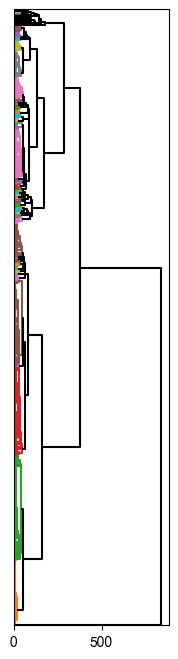

In [8]:
#Use scipy clustering and dendrogram visualization to organize genes by their pN/pS values across samples

#Make a copy of the pN/pS df to cluster
X_b1 = bin_1_mean_pNpS_df.fillna(0).copy(deep=True)
#Run ward clustering on the df
Z_b1 = linkage(X_b1,method='ward')

#Set up the plot
plt.figure(figsize=(2,8))
dn_b1 = dendrogram(Z_b1,orientation='right',no_labels=True,color_threshold=50,above_threshold_color='black') #create the dendrogram and color the branches at a certain level
plt.show()

#get the order of the leaves to reindex the df for the heatmap
dendrogram_order_b1 = dn_b1['leaves']

#Create a df for the heatmap that's reordered based on the dendrogram
bin_1_mean_pNpS_df_clustered = bin_1_mean_pNpS_df.reset_index(drop=True).reindex(dendrogram_order_b1).astype(float)

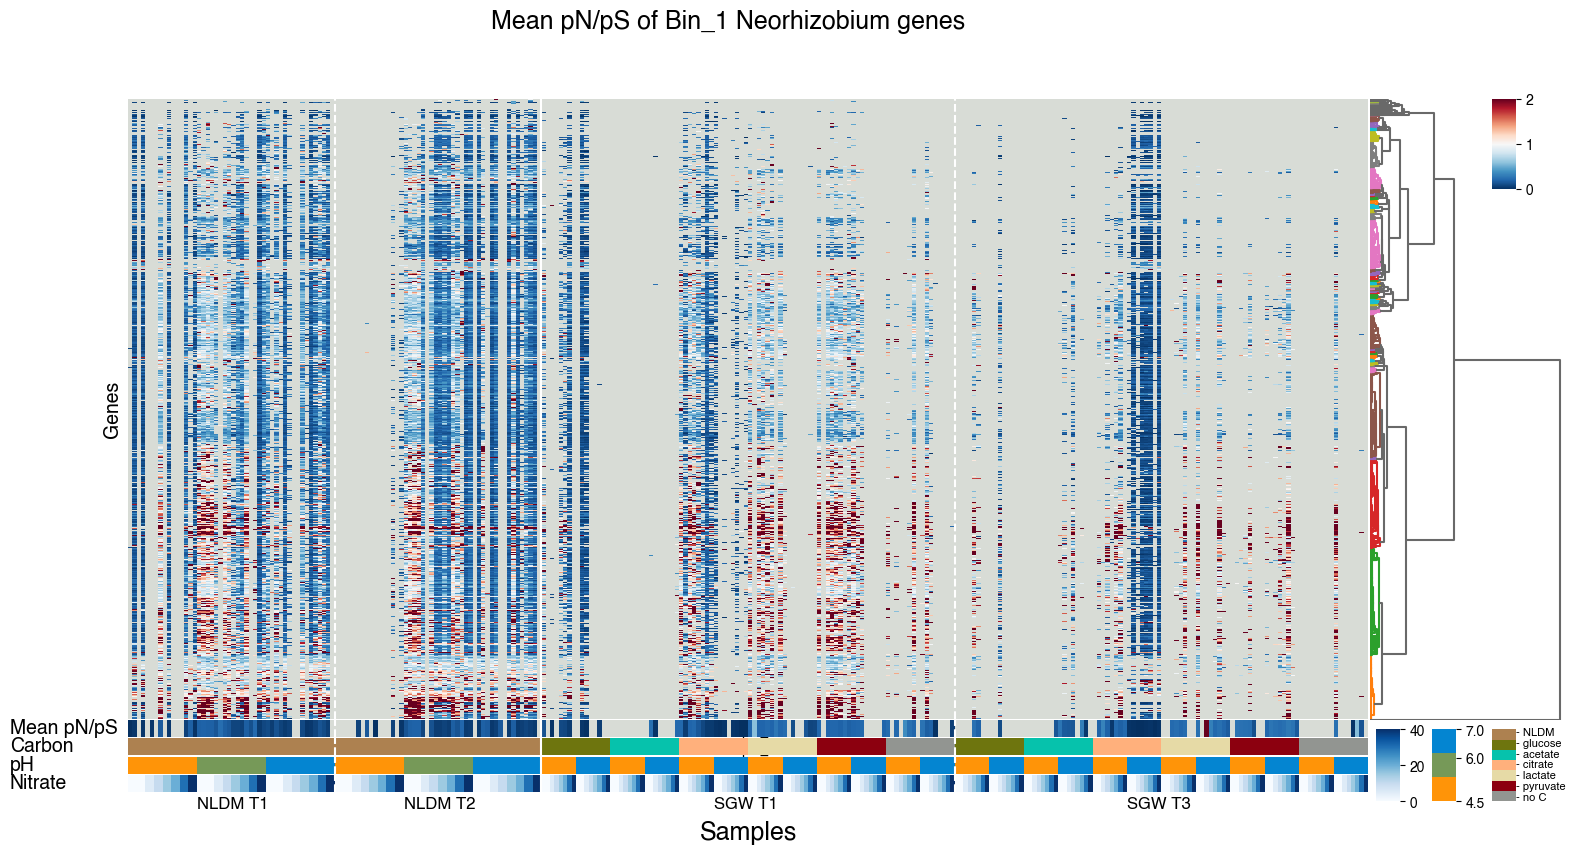

In [9]:
#Make a figure plotting the pN/pS value for each gene in each sample, organized the same way as the community composition data.

#Set up the plot
fig,ax = plt.subplots(ncols=1,nrows=5,figsize=(16,9),height_ratios=[4.55,.125,.125,.125,.125])

cbar_ax0 = fig.add_subplot([.9775,.78,.015,.1]) #additional axis for the colorbar where we want it

sns.heatmap(bin_1_mean_pNpS_df_clustered,cmap='RdBu_r',vmax=2,xticklabels=True,ax=ax[0],cbar=True,cbar_ax=cbar_ax0) #plot the data

#label the axes correctly
ax[0].set_ylabel('Genes',fontsize=14)
ax[0].set_yticks([])
ax[0].set_xticks([])
ax[0].axvline(48,color='white',ls='--') #add these lines to separate the media and time points
ax[0].axvline(96,color='white',ls='-')
ax[0].axvline(192,color='white',ls='--')
ax[0].text(16,6750,'NLDM T1',fontsize=12)
ax[0].text(64,6750,'NLDM T2',fontsize=12)
ax[0].text(136,6750,'SGW T1',fontsize=12)
ax[0].text(232,6750,'SGW T3',fontsize=12)
ax[0].set_facecolor('xkcd:light grey') #set the background to grey so that the genes with no data are grey

#add the dendrogram to see how it relates to the clustered genes
dn_ax0 = fig.add_subplot([0.901,.19,.125,.69])
dendrogram(Z_b1,orientation='right',no_labels=True,color_threshold=50,above_threshold_color='dimgray',ax=dn_ax0)
dn_ax0.set_xticks([])
dn_ax0.axis('off')

#colorbars for C, pH, and NO3-
cbar_ax1 = fig.add_subplot([.9775,.1,.015,.08])
cbar_ax2 = fig.add_subplot([.94,.1,.015,.08])
cbar_ax3 = fig.add_subplot([.905,.1,.015,.08])

#plot the mean pN/pS value for each sample. This might look a little skewed but helps explain the data a bit
sns.heatmap(pd.DataFrame(bin_1_mean_pNpS_df_clustered.mean().astype(float)).T,cmap='RdBu_r',ax=ax[1],yticklabels=False,cbar=False)
ax[1].axvline(48,color='white',ls='--')
ax[1].axvline(96,color='white',ls='-')
ax[1].axvline(192,color='white',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Mean pN/pS',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#plot the C
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8)
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[2].axvline(48,color='white',ls='--')
ax[2].axvline(96,color='white',ls='-')
ax[2].axvline(192,color='white',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('Carbon',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#plot the pH
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
cbar_ax2.set_yticks([4.5,6,7])
ax[3].axvline(48,color='white',ls='--')
ax[3].axvline(96,color='white',ls='-')
ax[3].axvline(192,color='white',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('pH',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

#plot the NO3
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[4],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
cbar_ax3.set_yticks([0,20,40])
ax[4].axvline(48,color='white',ls='--')
ax[4].axvline(96,color='white',ls='-')
ax[4].axvline(192,color='white',ls='--')
ax[4].set_xticks([])
ax[4].set_ylabel('Nitrate',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[4].set_facecolor('xkcd:light grey')

ax[4].set_xlabel('Samples',fontsize=18,labelpad=20)

plt.suptitle('Mean pN/pS of Bin_1 Neorhizobium genes',fontsize=18)

plt.subplots_adjust(hspace=0.01)

plt.show()

Total samples: 288
N samples with any pN/pS calculated: 184
Total genes: 5895
N samples with > 1000 genes with pN/pS calculated: 109


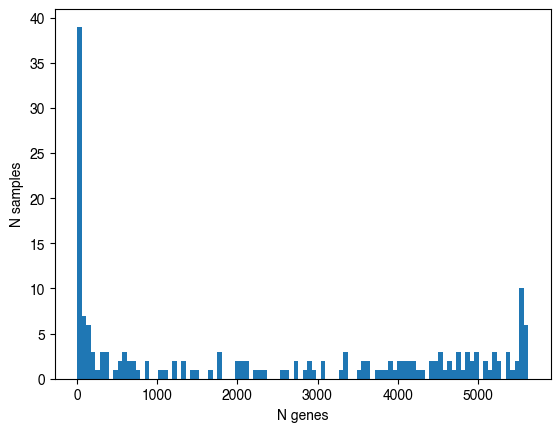

In [10]:
#Obviously, some data is missing so let's get a better idea of what we actually have
print('Total samples:',len(bin_1_mean_pNpS_df_clustered.T))
print('N samples with any pN/pS calculated:',len(bin_1_mean_pNpS_df_clustered.dropna(axis=1,how='all').T))
print('Total genes:',len(bin_1_mean_pNpS_df_clustered))
print('N samples with > 1000 genes with pN/pS calculated:',len([i for i in bin_1_mean_pNpS_df_clustered.dropna(axis=1,how='all').count() if i > 1000]))
bin_1_mean_pNpS_df_clustered.dropna(axis=1,how='all').count().plot(kind='hist',bins=100)
plt.ylabel('N samples')
plt.xlabel('N genes')
plt.show()

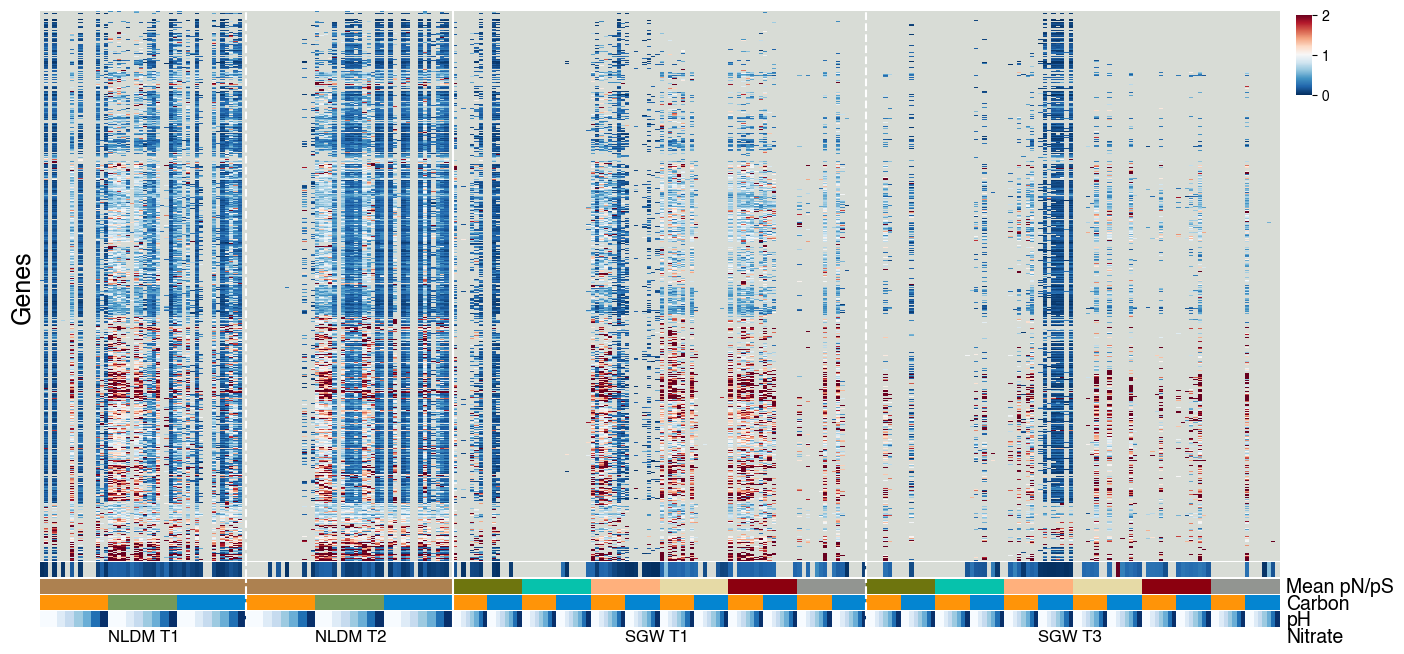

In [11]:
#Create a stripped down version of the plot above, dropping the dendrogram for figure size/space/legibility purposes

fig,ax = plt.subplots(ncols=1,nrows=5,figsize=(16,8),height_ratios=[4.55,.125,.125,.125,.125])

cbar_ax0 = fig.add_subplot([0.91,.775,.01,.1])
sns.heatmap(bin_1_mean_pNpS_df_clustered,cmap='RdBu_r',vmax=2,xticklabels=True,ax=ax[0],cbar=True,cbar_ax=cbar_ax0)

#set up axis labels
ax[0].set_ylabel('Genes',fontsize=18)
ax[0].set_xlabel('')
ax[0].set_yticks([])
ax[0].set_xticks([])
ax[0].axvline(48,color='white',ls='--')
ax[0].axvline(96,color='white',ls='-')
ax[0].axvline(192,color='white',ls='--')
ax[0].text(16,6750,'NLDM T1',fontsize=12)
ax[0].text(64,6750,'NLDM T2',fontsize=12)
ax[0].text(136,6750,'SGW T1',fontsize=12)
ax[0].text(232,6750,'SGW T3',fontsize=12)
ax[0].set_facecolor('xkcd:light grey')

#This is how we would add the dendrogram
#dn_ax0 = fig.add_subplot([0.901,.19,.125,.69])
#dendrogram(Z_b1,orientation='right',no_labels=True,color_threshold=50,above_threshold_color='dimgray',ax=dn_ax0)
#dn_ax0.set_xticks([])
#dn_ax0.axis('off')
#dn_ax0.set_xlabel('')

#Mean pN/pS values per sample
sns.heatmap(pd.DataFrame(bin_1_mean_pNpS_df_clustered.mean().astype(float)).T,cmap='RdBu_r',ax=ax[1],yticklabels=False,cbar=False)
ax[1].axvline(48,color='white',ls='--')
ax[1].axvline(96,color='white',ls='-')
ax[1].axvline(192,color='white',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Mean pN/pS',fontsize=14,labelpad=5,rotation=0,loc='bottom')
ax[1].set_xlabel('')
ax[1].yaxis.set_label_position("right")
ax[1].set_facecolor('xkcd:light grey')

#C labels per sample
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
ax[2].axvline(48,color='white',ls='--')
ax[2].axvline(96,color='white',ls='-')
ax[2].axvline(192,color='white',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('Carbon',fontsize=14,labelpad=5,rotation=0,loc='bottom')
ax[2].set_xlabel('')
ax[2].yaxis.set_label_position("right")
ax[2].set_facecolor('xkcd:light grey')

#pH labels per sample
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
ax[3].axvline(48,color='white',ls='--')
ax[3].axvline(96,color='white',ls='-')
ax[3].axvline(192,color='white',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('pH',fontsize=14,labelpad=5,rotation=0,loc='bottom')
ax[3].set_xlabel('')
ax[3].yaxis.set_label_position("right")
ax[3].set_facecolor('xkcd:light grey')

#NO3- per sample
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[4],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
ax[4].axvline(48,color='white',ls='--')
ax[4].axvline(96,color='white',ls='-')
ax[4].axvline(192,color='white',ls='--')
ax[4].set_xticks([])
ax[4].set_ylabel('Nitrate',fontsize=14,labelpad=5,rotation=0,loc='bottom')
ax[4].set_xlabel('')
ax[4].yaxis.set_label_position("right")
ax[4].set_facecolor('xkcd:light grey')

ax[4].set_xlabel('')

plt.subplots_adjust(hspace=0.01)

#plt.savefig('../figs/fig4A_gene-pnps-clustmap.png',dpi=300,bbox_inches='tight')

plt.show()

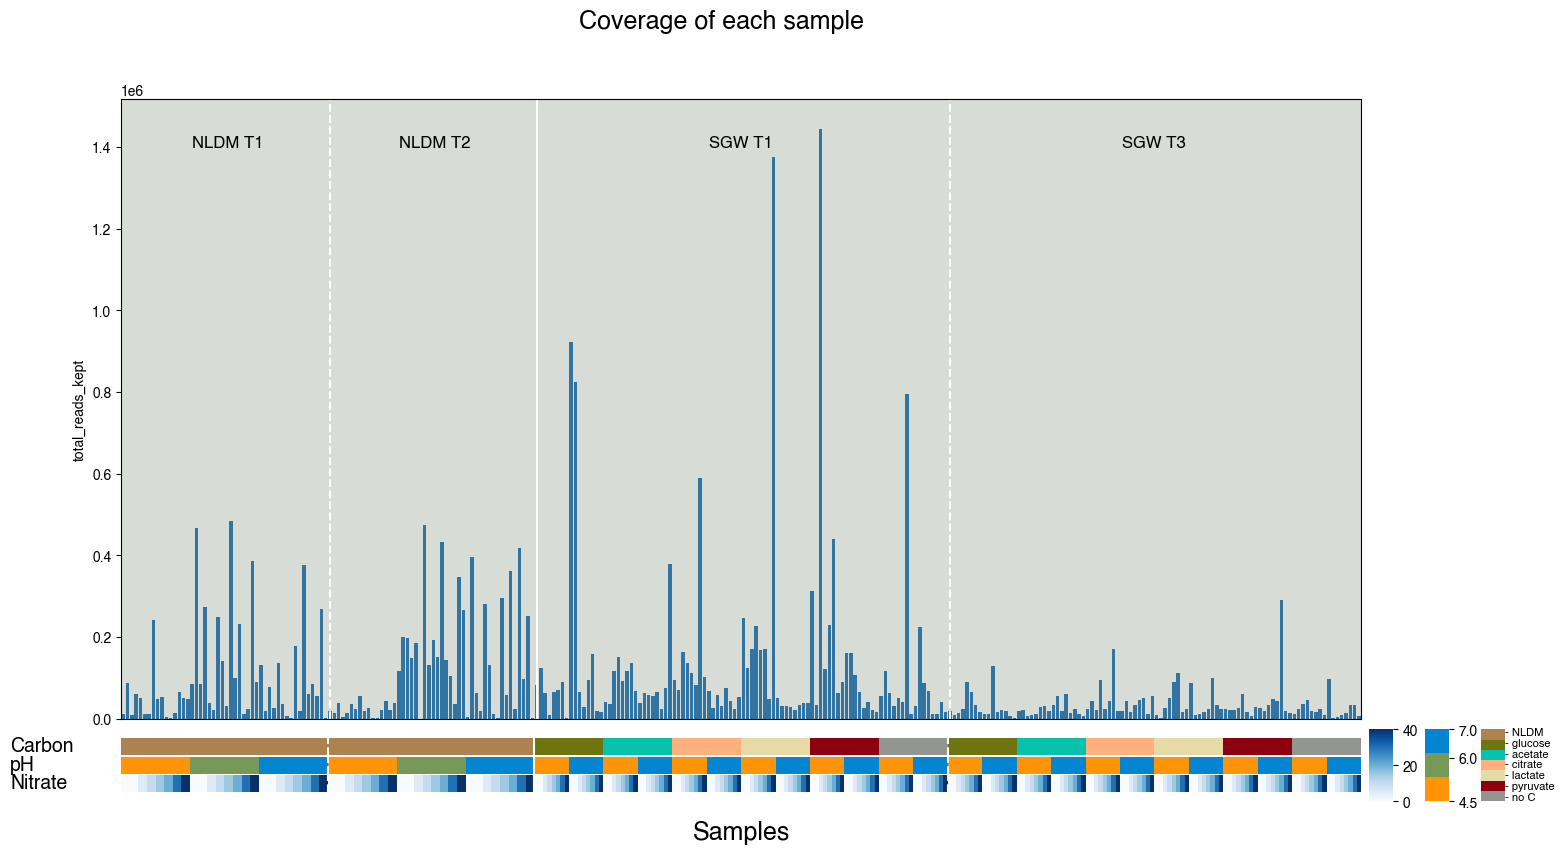

In [12]:
#The lack of values in SGW acetate is strange since Neo is abundant in those samples.
#Let's read in some sample info and see if coverage explains this

sample_metadata_df = pd.read_csv('./data/SUMMARY_manual_bins/misc_data_layers/default.txt',sep='\t') #this includes sample counts, coverage, etc.
sample_metadata_df = sample_metadata_df.set_index('layers').reindex(sample_order).reset_index() #reorder to match the plot above

#Create the same plot but this time with total coverage/reads kept per sample
fig,ax = plt.subplots(ncols=1,nrows=5,figsize=(16,9),height_ratios=[4.55,.125,.125,.125,.125])

sns.barplot(sample_metadata_df,x='layers',y='total_reads_kept',ax=ax[0])

ax[0].set_xlabel('')
ax[0].set_xticks([])
ax[0].axvline(48,color='white',ls='--')
ax[0].axvline(96,color='white',ls='-')
ax[0].axvline(192,color='white',ls='--')
ax[0].text(16,1.4e6,'NLDM T1',fontsize=12)
ax[0].text(64,1.4e6,'NLDM T2',fontsize=12)
ax[0].text(136,1.4e6,'SGW T1',fontsize=12)
ax[0].text(232,1.4e6,'SGW T3',fontsize=12)
ax[0].set_facecolor('xkcd:light grey')

cbar_ax1 = fig.add_subplot([.975,.1,.015,.08])
cbar_ax2 = fig.add_subplot([.94,.1,.015,.08])
cbar_ax3 = fig.add_subplot([.905,.1,.015,.08])

ax[1].axis('off')

sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8)
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[2].axvline(48,color='white',ls='--')
ax[2].axvline(96,color='white',ls='-')
ax[2].axvline(192,color='white',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('Carbon',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
cbar_ax2.set_yticks([4.5,6,7])
ax[3].axvline(48,color='white',ls='--')
ax[3].axvline(96,color='white',ls='-')
ax[3].axvline(192,color='white',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('pH',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[4],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
cbar_ax3.set_yticks([0,20,40])
ax[4].axvline(48,color='white',ls='--')
ax[4].axvline(96,color='white',ls='-')
ax[4].axvline(192,color='white',ls='--')
ax[4].set_xticks([])
ax[4].set_ylabel('Nitrate',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[4].set_facecolor('xkcd:light grey')

ax[4].set_xlabel('Samples',fontsize=18,labelpad=20)

plt.suptitle('Coverage of each sample',fontsize=18)

plt.subplots_adjust(hspace=0.01)

plt.show()

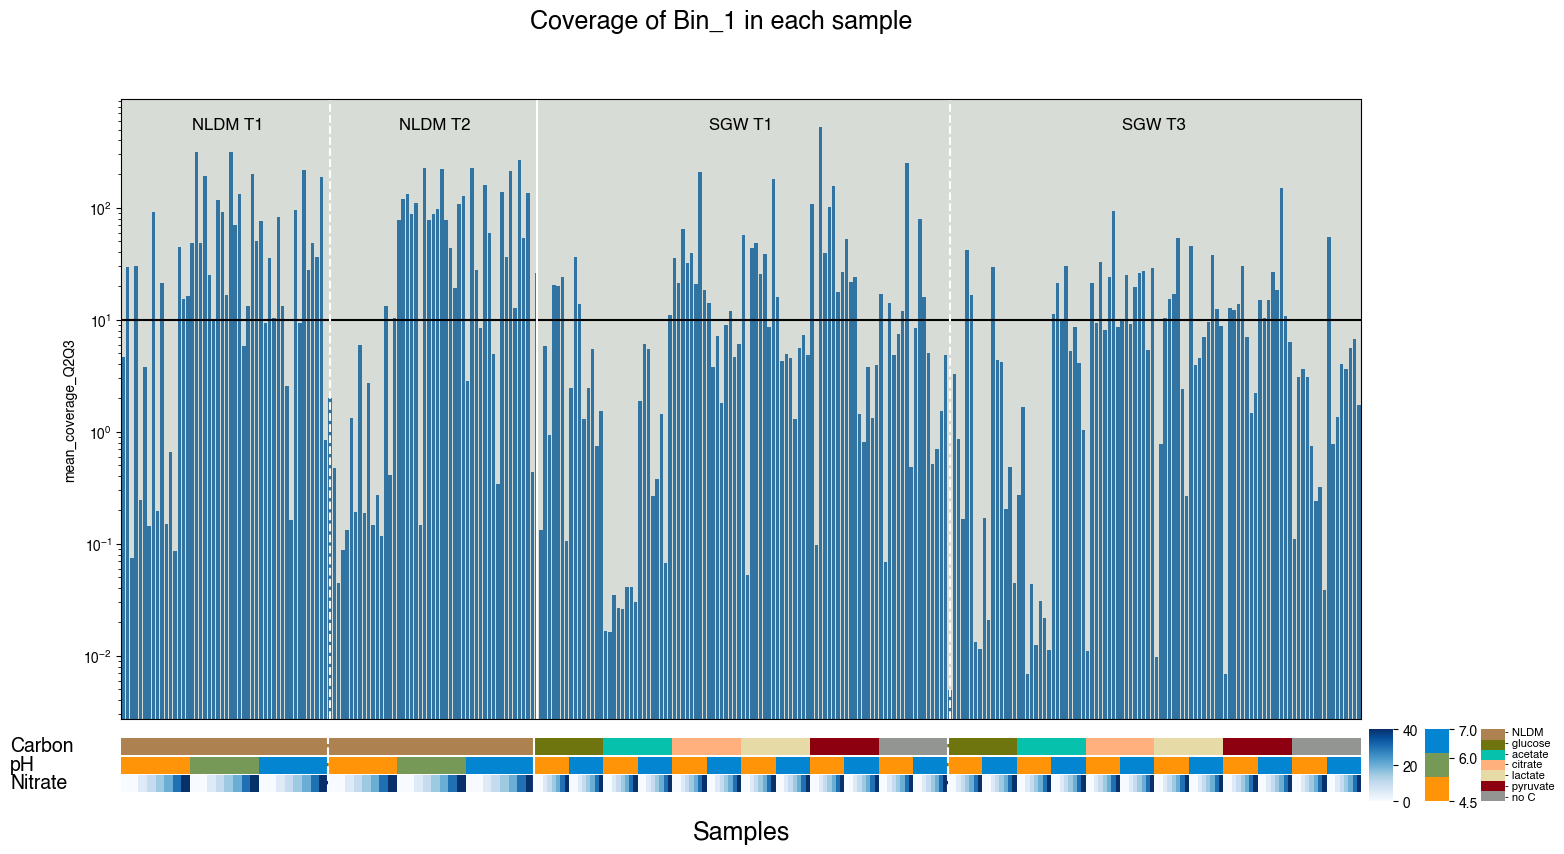

In [13]:
#Check just the coverage of Bin_1

bin_1_cov = pd.read_csv('./data/SUMMARY_manual_bins/bin_by_bin/Bin_1/Bin_1-mean_coverage_Q2Q3.txt',sep='\t',index_col='bin').T.reindex(sample_order).reset_index().rename({'index':'samples'},axis=1)
bin_1_cov

fig,ax = plt.subplots(ncols=1,nrows=5,figsize=(16,9),height_ratios=[4.55,.125,.125,.125,.125])

sns.barplot(bin_1_cov,x='samples',y='mean_coverage_Q2Q3',ax=ax[0])

#ax[0].set_ylabel('Genes',fontsize=14)
ax[0].set_yscale('log')
ax[0].set_xlabel('')
ax[0].set_xticks([])
ax[0].axhline(10,color='black')
ax[0].axvline(48,color='white',ls='--')
ax[0].axvline(96,color='white',ls='-')
ax[0].axvline(192,color='white',ls='--')
ax[0].text(16,500,'NLDM T1',fontsize=12)
ax[0].text(64,500,'NLDM T2',fontsize=12)
ax[0].text(136,500,'SGW T1',fontsize=12)
ax[0].text(232,500,'SGW T3',fontsize=12)
ax[0].set_facecolor('xkcd:light grey')

cbar_ax1 = fig.add_subplot([.975,.1,.015,.08])
cbar_ax2 = fig.add_subplot([.94,.1,.015,.08])
cbar_ax3 = fig.add_subplot([.905,.1,.015,.08])

ax[1].axis('off')

sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8)
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[2].axvline(48,color='white',ls='--')
ax[2].axvline(96,color='white',ls='-')
ax[2].axvline(192,color='white',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('Carbon',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
cbar_ax2.set_yticks([4.5,6,7])
ax[3].axvline(48,color='white',ls='--')
ax[3].axvline(96,color='white',ls='-')
ax[3].axvline(192,color='white',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('pH',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[4],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
cbar_ax3.set_yticks([0,20,40])
ax[4].axvline(48,color='white',ls='--')
ax[4].axvline(96,color='white',ls='-')
ax[4].axvline(192,color='white',ls='--')
ax[4].set_xticks([])
ax[4].set_ylabel('Nitrate',fontsize=14,labelpad=80,rotation=0,loc='bottom')
ax[4].set_facecolor('xkcd:light grey')

ax[4].set_xlabel('Samples',fontsize=18,labelpad=20)

plt.suptitle('Coverage of Bin_1 in each sample',fontsize=18)

plt.subplots_adjust(hspace=0.01)

plt.show()

In [14]:
sample_metadata_df

,layers,num_INDELs_reported,total_reads_mapped,num_SCVs_reported,num_SNVs_reported,total_reads_kept,Timepoint,Media,pH,C source,[NO3]
0,NLDM_T1_A1,26,11577,458,612,11577,T1,NLDM,4.5,NLDM,0
1,NLDM_T1_A8,13583,88334,227747,294250,88334,T1,NLDM,4.5,NLDM,0
2,NLDM_T1_B1,84,8275,2226,3035,8275,T1,NLDM,4.5,NLDM,0
3,NLDM_T1_B8,15240,60217,220245,286041,60217,T1,NLDM,4.5,NLDM,0
4,NLDM_T1_A2,108,50547,149,460,50546,T1,NLDM,4.5,NLDM,5
...,...,...,...,...,...,...,...,...,...,...,...
283,SGW_T3_F7,17,9911,23,60,9911,T3,SGW,7.0,no C,10
284,SGW_T3_E7,41,13703,103,290,13703,T3,SGW,7.0,no C,15
285,SGW_T3_D7,354,33180,2779,3899,33180,T3,SGW,7.0,no C,20
286,SGW_T3_C7,736,34377,5232,7078,34377,T3,SGW,7.0,no C,30


In [15]:
#Now let's look at correlations of pN/pS and Bin/sample coverage
b1_mean_pnps_df = pd.DataFrame(bin_1_mean_pNpS_df.mean().astype(float)).reset_index().rename({'sample_id':'samples',0:'mean_pNpS'},axis=1)
b1_mean_pnps_df = b1_mean_pnps_df.merge(bin_1_cov,how='left',on='samples')
b1_mean_pnps_df = b1_mean_pnps_df.merge(sample_metadata_df.rename({'layers':'samples'},axis=1),how='left',on='samples')
b1_mean_pnps_df

,samples,mean_pNpS,mean_coverage_Q2Q3,num_INDELs_reported,total_reads_mapped,num_SCVs_reported,num_SNVs_reported,total_reads_kept,Timepoint,Media,pH,C source,[NO3]
0,NLDM_T1_A1,0.174300,4.693395,26,11577,458,612,11577,T1,NLDM,4.5,NLDM,0
1,NLDM_T1_A8,0.315740,29.786401,13583,88334,227747,294250,88334,T1,NLDM,4.5,NLDM,0
2,NLDM_T1_B1,NaN,0.074371,84,8275,2226,3035,8275,T1,NLDM,4.5,NLDM,0
3,NLDM_T1_B8,0.288541,30.186001,15240,60217,220245,286041,60217,T1,NLDM,4.5,NLDM,0
4,NLDM_T1_A2,NaN,0.246516,108,50547,149,460,50546,T1,NLDM,4.5,NLDM,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,SGW_T3_F7,NaN,4.003012,17,9911,23,60,9911,T3,SGW,7.0,no C,10
284,SGW_T3_E7,0.238458,3.629595,41,13703,103,290,13703,T3,SGW,7.0,no C,15
285,SGW_T3_D7,3.432536,5.614572,354,33180,2779,3899,33180,T3,SGW,7.0,no C,20
286,SGW_T3_C7,0.929217,6.680390,736,34377,5232,7078,34377,T3,SGW,7.0,no C,30


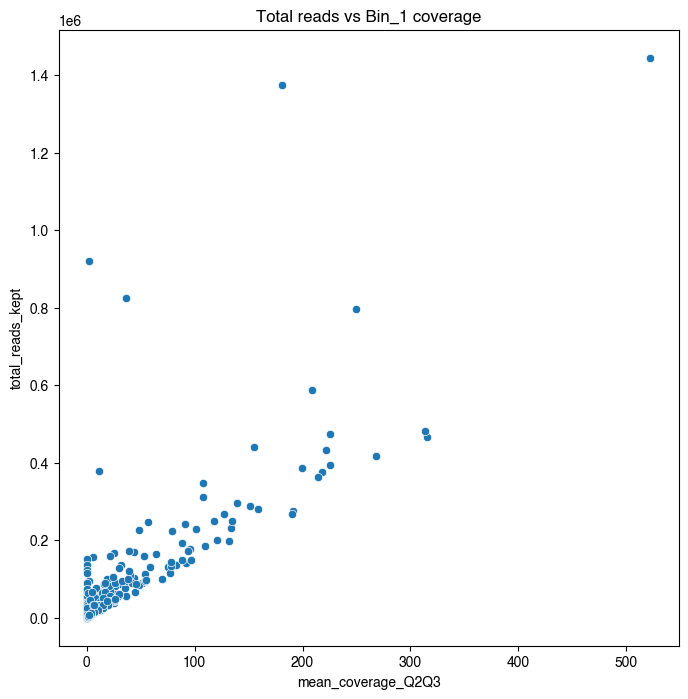

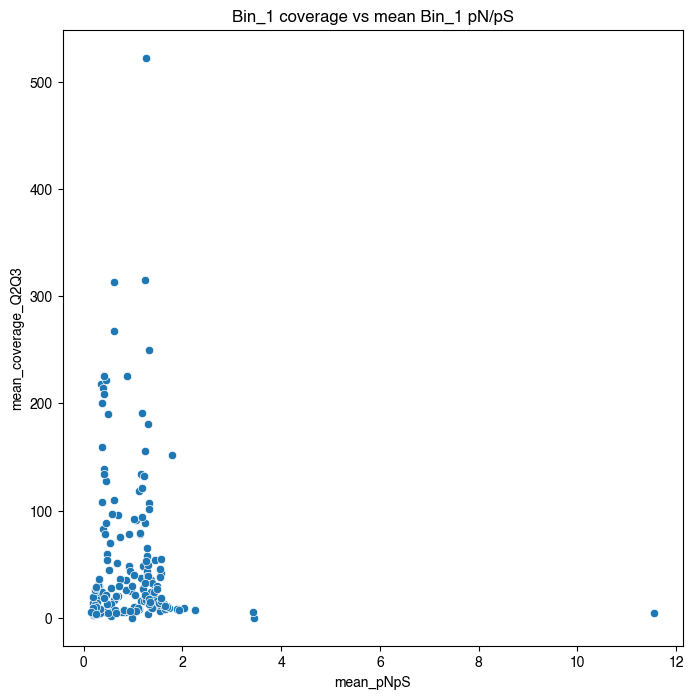

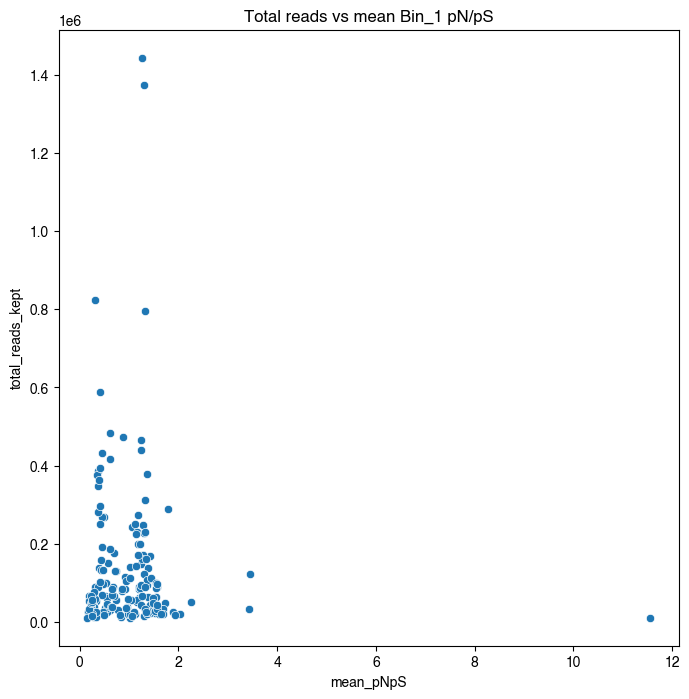

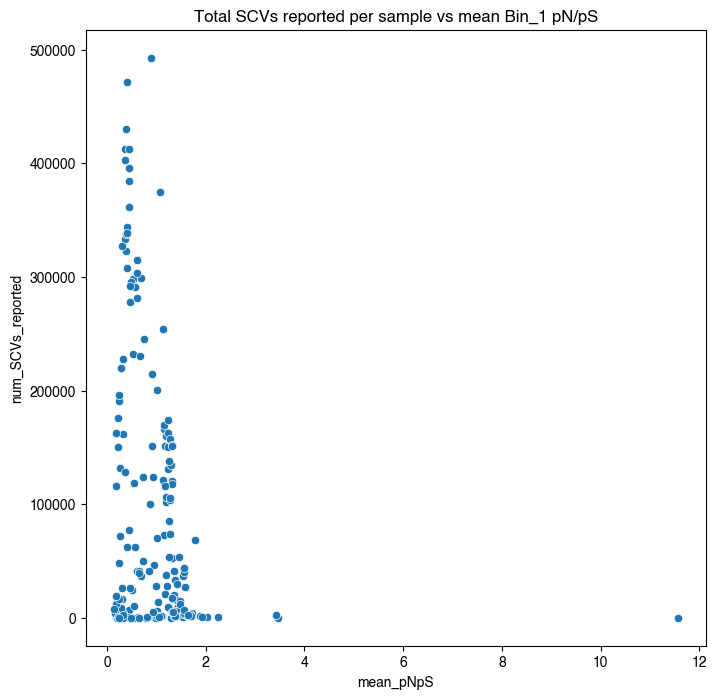

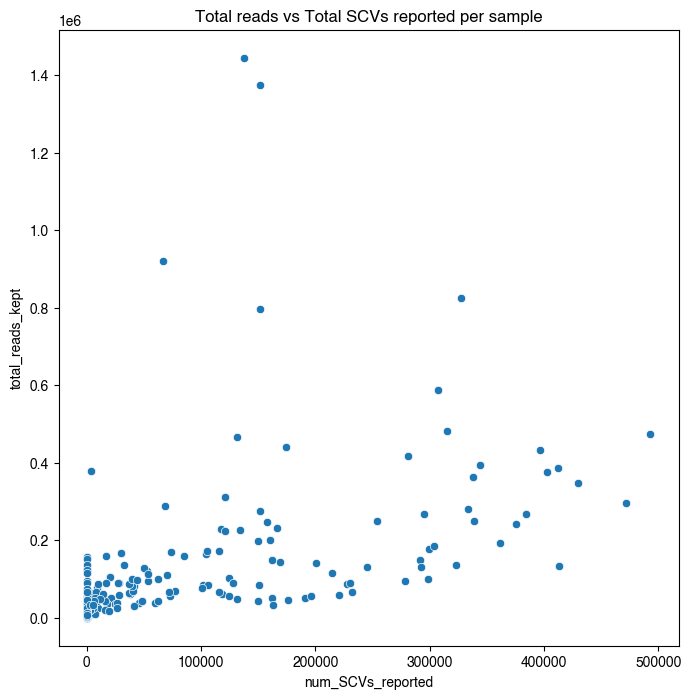

In [16]:
#The data show that pN/pS is relatively stable from low to high coverage, except at very low coverage where the pN/pS can become very high

plt.figure(figsize=(8,8))
sns.scatterplot(b1_mean_pnps_df,x='mean_coverage_Q2Q3',y='total_reads_kept')
plt.title('Total reads vs Bin_1 coverage')
plt.show()

plt.figure(figsize=(8,8))
sns.scatterplot(b1_mean_pnps_df,x='mean_pNpS',y='mean_coverage_Q2Q3')
plt.title('Bin_1 coverage vs mean Bin_1 pN/pS')
plt.show()

plt.figure(figsize=(8,8))
sns.scatterplot(b1_mean_pnps_df,x='mean_pNpS',y='total_reads_kept')
plt.title('Total reads vs mean Bin_1 pN/pS')
plt.show()

plt.figure(figsize=(8,8))
sns.scatterplot(b1_mean_pnps_df,x='mean_pNpS',y='num_SCVs_reported')
plt.title('Total SCVs reported per sample vs mean Bin_1 pN/pS')
plt.show()

plt.figure(figsize=(8,8))
sns.scatterplot(b1_mean_pnps_df,x='num_SCVs_reported',y='total_reads_kept')
plt.title('Total reads vs Total SCVs reported per sample')
plt.show()

In [17]:
#Assign ids to each cluster of genes below the cutoff so that we can check the functions of different clusters

cluster_list = [] #add numerical cluster numbers here
count = 0 #initiate the counter
for i in range(len(dn_b1['leaves_color_list'])): #check the color listed for each gene in the dendrogram order
    if dn_b1['leaves_color_list'][i] == dn_b1['leaves_color_list'][i-1]: #Check to see if each gene matches the previous, if it matches add to same cluster number
        cluster_list.append(count)
    elif dn_b1['leaves_color_list'][i] != dn_b1['leaves_color_list'][i-1]: #if it doesn't match, move to next number and add it to the list
        count += 1
        cluster_list.append(count)

#Get an ordered list of gene_callers_ids by keeping the original index while reindexing to match the cluster order
d1_ordered_gene_id_list = bin_1_mean_pNpS_df.reset_index().reindex(dendrogram_order_b1)['corresponding_gene_call'].to_list()
#Combine the gene_callers_id list with the cluster list so we can match functions to each gene; then merge with the gene calls and functions
cluster_gene_df = pd.DataFrame({'gene_callers_id':d1_ordered_gene_id_list,'cluster':cluster_list}).merge(bin_1_gene_calls_df,how='left',on='gene_callers_id')

cluster_gene_df

,gene_callers_id,cluster,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),...,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
0,84620,0,contig_18,4171,4363,r,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGGCCGGGGCTGTAGCTCAGCTGGGAGAGCACCTGCTTTGCAAGC...
1,140970,1,contig_3,3405447,3406152,f,Pathway modules; Energy metabolism; ATP synthesis,M00157,"F-type ATPase, prokaryotes and chloroplasts",M00157,...,C,F-type H+-transporting ATPase subunit a,K02108,FoF1-type ATP synthase,COG0356,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko00001!!!ko00194!!!ko03110,"FoF1-type ATP synthase, membrane subunit a (At...",COG0356,ATGACCTCGCCGCTCGAAATCACGCCGCTTTTCTTTCTAGGCCCTG...
2,19625,1,contig_953,76522,76888,f,NaN,NaN,NaN,NaN,...,S,NaN,NaN,NaN,NaN,NaN,NaN,Uncharacterized conserved protein,COG4683,ATGACGGAATGGAAGGTCGAGTTTCATGACCGCTTCAAAAGCGAGA...
3,93695,1,contig_11,555443,555731,r,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTGAGACCTTTGCCTCGGCGCTCCAAGGCCCGCAGCAAAGCCTCCT...
4,41183,1,contig_2094,245073,245400,r,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGAAATCGGTAGGTCGGTGCCTGTCGGCGGCAACACTCATCTGCG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5890,139946,83,contig_3,2310472,2312305,f,NaN,NaN,NaN,NaN,...,T!!!T,methyl-accepting chemotaxis protein,K03406,NaN,NaN,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02035,Methyl-accepting chemotaxis protein (MCP) (Tar...,COG0840!!!COG4564,ATGAAACGTCTTACAATTTCCTGGCGGCTTTATTGTCTTGTGCTTC...
5891,32773,83,contig_8,229158,229980,f,NaN,NaN,NaN,NaN,...,P,NitT/TauT family transport system permease pro...,K02050,NaN,NaN,"Transporters>>>ABC transporters, prokaryotic t...",ko02000,ABC-type nitrate/sulfonate/bicarbonate transpo...,COG0600,ATGAGCCAGGTCGTCTCATCCCGGGTCGATACGGAGCGCAAGATCG...
5892,33464,83,contig_8,980409,980964,r,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTGAGTGACTTTGAAGGCGCACCTACCGAATTGCTGGAAATGCCGA...
5893,76435,84,contig_20,81069,81657,f,NaN,NaN,NaN,NaN,...,J!!!O,NaN,NaN,NaN,NaN,NaN,NaN,"Protein N-acetyltransferase, RimJ/RimL family ...",COG1670,ATGAACGCTGCCGTTCTCCAGAAGAGCGATTCTGTCGTCACGATGC...


In [18]:
#Perform a hypergeometric test to determine if there is functional enrichment for each cluster (from the Ward clustering)
#Let's generate some stats to determine functional enrichment in clusters using scipy.stats.hypergeom sf 
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
#First step is to get the background distribution of functions in the genome:
KEGG_path_dist = cluster_gene_df['COG20_CATEGORY'].str.split('!!!',expand=True)[0].fillna('Unknown').value_counts()

#Then, we want to get the path distributions for each cluster
cluster_list = list(set(cluster_list)) #easy cluster list to iterate over
cluster_KEGG_value_counts_dict = {} #dict to connect each cluster with its distribution of functions
for cluster in cluster_list: #loop to get function distribution in each cluster
    cluster_df = cluster_gene_df[cluster_gene_df['cluster']==cluster] #subsetting table with functional info to only genes in cluster
    cluster_KEGG_path_counts = cluster_df['COG20_CATEGORY'].str.split('!!!',expand=True)[0].fillna('Unknown').value_counts() #calc. dist.
    cluster_KEGG_value_counts_dict[cluster] = cluster_KEGG_path_counts #add to dict

#We're going to want to get the value for each module in the distribution series, so let's make it into a dict for easy access
KEGG_path_dist_dict = KEGG_path_dist.to_dict() #the value_counts series is useful, but I also want it as a dict for easy looping
#Create empty lists to build df with data
cluster_num_list = [] #add cluster num for each test
cluster_pval_list = [] #add pvals here from hypergeom.sf
cluster_function_list = [] #add function here for each test
M = KEGG_path_dist.values.sum() #total population size (number of genes) variable for the hypergeometric sf test
for cluster in cluster_list:
    cluster_dist = cluster_KEGG_value_counts_dict[cluster]
    N = cluster_dist.values.sum() #total size of sample (genes in cluster)
    index = 0 #use an index counter for easy looping through series
    for function in cluster_dist.index: #check abundance for each function
        n = KEGG_path_dist_dict[function] #abundance of function in in genome
        if n < 3: #ignore small counts
            continue
        x = cluster_dist.values[index] #abundance of function in cluster
        index += 1 #step index for next function and value
        pval = hypergeom.sf(x-1,M,n,N) #run the test
        cluster_num_list.append(cluster) #add cluster num to list
        cluster_pval_list.append(pval) #add pval to list
        cluster_function_list.append(function) #add function to list

#put the results together in a df
df_cluster_pval = pd.DataFrame({'cluster':cluster_num_list,
                                     'p-value':cluster_pval_list,
                                     'COG function':cluster_function_list})

#Then, we need to run a multiple testing correction for the number of times we run this test 
rej, pval_corr = multipletests(df_cluster_pval['p-value'].values.astype(float), method='fdr_bh',alpha=0.05)[:2] #Benjamini-Hochberg correction
df_cluster_pval['BH-corrected p-value'] = pval_corr #add the corrected p-value to the df
#df_cluster_pval = df_cluster_pval[df_cluster_pval['BH-corrected p-value'] <= 0.05] #Let's drop anything below our significance cutoff
#The multiple testing correction is a bit too stringent here, so let's ignore it for now but keep it for informational purposes
df_cluster_pval[df_cluster_pval['BH-corrected p-value']<=0.05].sort_values(by='BH-corrected p-value')[0:25]

,cluster,p-value,COG function,BH-corrected p-value
1,1,1.021768e-39,Unknown,8.378499e-37
632,44,2.895657e-13,Unknown,1.187219e-10
23,2,1.739610e-12,Unknown,4.754933e-10
2,1,1.239373e-08,Function unknown,2.540714e-06
611,43,1.325432e-04,Unknown,1.811424e-02
651,45,1.145492e-04,Transcription,1.811424e-02


In [19]:
#This didn't really tell me a whole lot, so I'm leaving it out for now
list(cluster_gene_df[cluster_gene_df['cluster']==1]['KEGG_Module'].unique())

['F-type ATPase, prokaryotes and chloroplasts',
 nan,
 'Citrate cycle (TCA cycle, Krebs cycle)!!!Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate!!!Reductive citrate cycle (Arnon-Buchanan cycle)!!!Succinate dehydrogenase, prokaryotes!!!Anoxygenic photosynthesis in green nonsulfur bacteria!!!Anoxygenic photosynthesis in green sulfur bacteria',
 'Catechol meta-cleavage, catechol => acetyl-CoA / 4-methylcatechol => propanoyl-CoA',
 'Ethylmalonyl pathway!!!Fatty acid biosynthesis, elongation!!!Fatty acid biosynthesis in mitochondria, fungi!!!Pimeloyl-ACP biosynthesis, BioC-BioH pathway, malonyl-ACP => pimeloyl-ACP',
 'Photorespiration',
 'De novo pyrimidine biosynthesis, glutamine (+ PRPP) => UMP',
 'Histidine biosynthesis, PRPP => histidine',
 'Tetrahydrofolate biosynthesis, GTP => THF!!!Tetrahydrofolate biosynthesis, mediated by ribA and trpF, GTP => THF',
 'Hydroxyproline degradation, trans-4-hydroxy-L-proline => 2-oxoglutarate',
 'Riboflavin biosynthesis, plants a

In [20]:
#make a list of highest pN/pS values
top_25_pNpS_genes = bin_1_mean_pNpS_df.T.mean().sort_values(ascending=False)[0:25].index.to_list()
bottom_25_pNpS_genes = bin_1_mean_pNpS_df.T.mean().sort_values(ascending=True)[0:25].index.to_list()
bin_1_mean_pNpS_df.T.mean().sort_values(ascending=False)[0:25]

corresponding_gene_call
84620     42.384676
93255     10.111749
19792      7.173249
93690      6.305894
19564      6.157835
41404      6.148937
137707     5.976694
33228      5.964699
139755     5.919469
138292     5.905961
19573      5.754132
138199     5.694361
138279     5.648368
140975     5.299437
19782      5.257811
140849     5.138216
19716      5.095238
138086     4.928037
140806     4.919157
138185     4.748153
137790     4.653562
138883     4.652677
138236     4.652027
41504      4.586247
32725      4.585567
dtype: float64

In [21]:
#Most of the top genes have no functional annotation, most here don't. This is probably spurious data, potentially related to coverage or simply genes that don't get transcribed.
#The top gene with an annotation is 41404, which is identified as a peptide/nickel/amino acid ABC-type transport system
bin_1_gene_calls_df[bin_1_gene_calls_df['gene_callers_id'].isin(top_25_pNpS_genes)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
17,19564,contig_953,14533,14866,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTGAAAGTCCATTGCAATGAAGGAGTAGCGATCCGCATTGACCCCG...
26,19573,contig_953,26138,27128,f,NaN,NaN,NaN,NaN,"Posttranslational modification, protein turnov...",O,peptide/nickel transport system ATP-binding pr...,K02032,NaN,NaN,KEGG Orthology (KO)>>>09140 Cellular Processes...,ko00001!!!ko02000,ABC-type glutathione transport system ATPase c...,COG1123,ATGACCCCGATCCTCACCATTCGCGACCTCTCCATGCGCTTCTCCA...
169,19716,contig_953,166293,166623,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGGGCGAGATCAAGCACCTCTCGGATCACAATCTTTCACGCGATC...
235,19782,contig_953,232319,232568,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGAAAAAGACGGCCGTCGCCGCAACACTTTTCGCGGCTCTTTCGC...
245,19792,contig_953,239215,239548,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTGAAAGTCCATTGCAATGAAGGAGTAGCGATCCGCATTGACCCCG...
419,32725,contig_8,183252,183885,f,Pathway modules; Energy metabolism; Methane me...,M00935,Methanofuran biosynthesis,M00935,Coenzyme transport and metabolism,H,5-(aminomethyl)-3-furanmethanol phosphate kina...,K07144,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko01000,5-(aminomethyl)-3-furanmethanol-phosphate kina...,COG2054,ATGACGCCGCTGGTGGTCAAGCTTGGAGGAAGCACGGCCGGCCGCA...
922,33228,contig_8,747959,748124,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGTATTTTCTGCCGATCCCCGATTGGCAGGCAAAAAAAACCGCGC...
1737,41404,contig_2094,476717,477707,f,NaN,NaN,NaN,NaN,Amino acid transport and metabolism!!!Inorgani...,E!!!P,peptide/nickel transport system ATP-binding pr...,K02031,NaN,NaN,KEGG Orthology (KO)>>>09140 Cellular Processes...,ko00001!!!ko02000,ABC-type dipeptide/oligopeptide/nickel transpo...,COG0444,ATGAGCCATCTCCAGGAAAAACATCCGGTCCTCGAGTTGATCAATC...
1837,41504,contig_2094,585329,586205,r,Pathway modules; Carbohydrate metabolism; Cent...,M00004!!!M00007!!!M00165!!!M00611!!!M00612,Pentose phosphate pathway (Pentose phosphate c...,M00004!!!M00007!!!M00165!!!M00611!!!M00612,Carbohydrate transport and metabolism,G,transketolase [EC:2.2.1.1],K00615,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09101...,ko00001!!!ko00001!!!ko00001!!!ko01000,"Transketolase, N-terminal subunit (TktA1)",COG3959,ATGAGTAATGTCAACAGCCGAGACCGGCAGCCTGCCCTGCGAGTTC...
2065,84620,contig_18,4171,4363,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGGCCGGGGCTGTAGCTCAGCTGGGAGAGCACCTGCTTTGCAAGC...


In [22]:
#Most of these lowest value genes appear to be related to essential cellular function. It is good that that makes sense!
bin_1_gene_calls_df[bin_1_gene_calls_df['gene_callers_id'].isin(bottom_25_pNpS_genes)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
712,33018,contig_8,522670,522871,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGCGACACTTTTTCAAAATGCTCAGGAACAGACTGAAGGGGACCC...
887,33193,contig_8,701563,701791,r,NaN,NaN,NaN,NaN,"Translation, ribosomal structure and biogenesis",J,small subunit ribosomal protein S21,K02970,Ribosome 30S subunit,COG0828,KEGG Orthology (KO)>>>09120 Genetic Informatio...,ko00001!!!ko03011!!!ko03011,Ribosomal protein S21 (RpsU) (PDB:4V4H),COG0828,GTGCAGGTACTAGTCCGCGACAACAATGTCGATCAGGCGCTCCGCG...
960,33266,contig_8,790141,790414,r,NaN,NaN,NaN,NaN,Function unknown,S,NaN,NaN,NaN,NaN,NaN,NaN,"Uncharacterized conserved protein, UPF0335 fam...",COG3750,ATGTCTGATGCTCATGGCGTCGCCCGCGACCAACTCCGCGCATTTG...
1033,33339,contig_8,858632,858791,r,NaN,NaN,NaN,NaN,"Replication, recombination and repair",L,NaN,NaN,NaN,NaN,NaN,NaN,"Endonuclease YncB, thermonuclease family (YncB)",COG1525,ATGCCAGACAATGTCATCAAGTTCCAGCGTCCGCCAAAACCGAAGC...
1541,41208,contig_2094,267428,267584,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGTCTGATGCTCAAATCGGTCTCGTGATGGCCGCTCCGATCATTG...
1723,41390,contig_2094,461083,461455,r,NaN,NaN,NaN,NaN,Transcription,K,NaN,NaN,NaN,NaN,NaN,NaN,"Predicted transcriptional regulator, contains ...",COG3620,ATGACTGCACATGCATTTGAAATGAGCGCCGCCTCCTTCAGTGAGG...
1905,76385,contig_20,30477,30762,r,NaN,NaN,NaN,NaN,Transcription,K,NaN,NaN,NaN,NaN,NaN,NaN,"DNA-binding transcriptional regulator, Lrp fam...",COG1522,ATGTCCATCATTGATCGCGCAGGCGATCCGACCGACGGGAAGACGT...
2150,93281,contig_11,88829,89111,f,NaN,NaN,NaN,NaN,Transcription!!!Signal transduction mechanisms,K!!!T,"BolA family transcriptional regulator, general...",K05527,NaN,NaN,Transcription factors>>>Prokaryotic type>>>Oth...,ko03000,DNA-binding global transcriptional regulator B...,COG0271,ATGTCCGTCAAAGCCCGGATCGAAGCCACGCTTACCGAAAACCTTG...
2155,93286,contig_11,93145,93304,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATGCCCACCCTTTTTCGTTTCCTCTTCGTGCTGGCGGTGATCGCAG...
2248,93379,contig_11,197254,197521,f,NaN,NaN,NaN,NaN,NaN,NaN,osmotically inducible lipoprotein OsmB,K04062,NaN,NaN,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,NaN,NaN,ATGAAGAAAGCCATCGTGCTTCTGATGCTTGGCGCATCCCTCGCGA...


In [23]:
bin_1_mean_pNpS_info_melt_df = bin_1_mean_pNpS_df.reset_index().melt(id_vars='corresponding_gene_call').rename({'corresponding_gene_call':'gene_callers_id','sample_id':'samples'},axis=1).merge(sample_info_df,on='samples',how='left')

mean_pnps_pH_4 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_pH_6 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 6]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_pH_7 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value'].replace([np.inf, -np.inf], np.nan).mean()

print(f'Mean pN/pS pH 4.5: {mean_pnps_pH_4:.2f}')
print(f'Mean pN/pS pH 6.0: {mean_pnps_pH_6:.2f}')
print(f'Mean pN/pS pH 7.0: {mean_pnps_pH_7:.2f}')

Mean pN/pS pH 4.5: 0.96
Mean pN/pS pH 6.0: 0.83
Mean pN/pS pH 7.0: 0.64


In [24]:
#Run t-tests (comparing all the genes found in all samples in each pH) on the pH pNpS data to see if those numbers are really different.

pH4_pNpS_values_bin_1 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value'].replace([np.inf, -np.inf], np.nan)
pH6_pNpS_values_bin_1 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 6]['value'].replace([np.inf, -np.inf], np.nan)
pH7_pNpS_values_bin_1 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value'].replace([np.inf, -np.inf], np.nan)

#The data is a little uneven, but the t-test results are strong either way
b1_stat_46,b1_p_46 = ttest_ind(pH4_pNpS_values_bin_1,pH6_pNpS_values_bin_1,nan_policy='omit',equal_var=False)
b1_stat_47,b1_p_47 = ttest_ind(pH4_pNpS_values_bin_1,pH7_pNpS_values_bin_1,nan_policy='omit',equal_var=False)
b1_stat_67,b1_p_67 = ttest_ind(pH6_pNpS_values_bin_1,pH7_pNpS_values_bin_1,nan_policy='omit',equal_var=False)

print(f'pH 4.5 vs 6 \t p = {b1_p_46:.2e}')
print(f'pH 4.5 vs 7 \t p = {b1_p_47:.2e}')
print(f'pH 6 vs 7 \t p = {b1_p_67:.2e}')

pH 4.5 vs 6 	 p = 3.39e-119
pH 4.5 vs 7 	 p = 0.00e+00
pH 6 vs 7 	 p = 3.84e-290


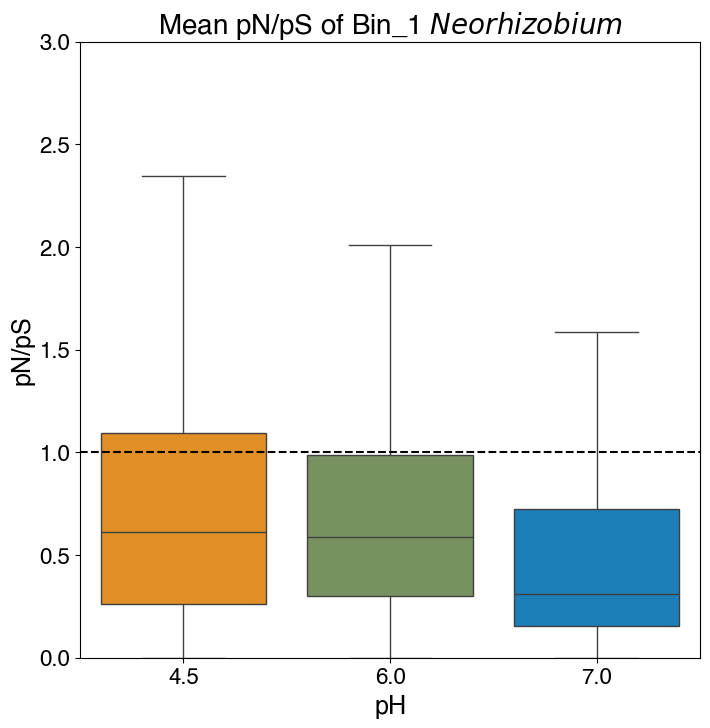

In [25]:
#Plot the pN/pS data from all samples

pH_palette = {4.5:'xkcd:tangerine',6:'xkcd:moss',7:'xkcd:cerulean'}
plt.figure(figsize=(8,8))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='pH',y='value',hue='pH',palette=pH_palette,showfliers=False,legend=False)
plt.ylim((0,3))
plt.title(r'Mean pN/pS of Bin_1 $\it{Neorhizobium}$',fontsize=20)
plt.axhline(1,color='black',linestyle='--')
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('pH',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

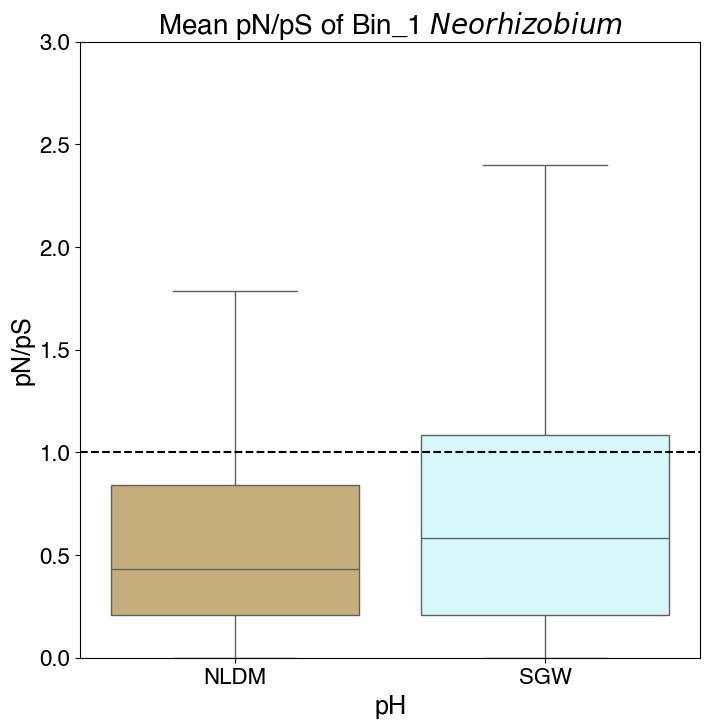

NLDM mean pN/pS = 0.69
SGW mean pN/pS = 0.96
Media t-test p = 0.00e+00


In [26]:
#Plot the pN/pS values (from) each medium
media_palette = {'NLDM':'xkcd:tan','SGW':'xkcd:pale blue'}

plt.figure(figsize=(8,8))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='Media',y='value',hue='Media',palette=media_palette,showfliers=False,legend=False)
#plt.yscale('log')
plt.ylim((0,3))
plt.title(r'Mean pN/pS of Bin_1 $\it{Neorhizobium}$',fontsize=20)
plt.axhline(1,color='black',linestyle='--')
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('pH',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

b1_NLDM_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM']['value']
b1_SGW_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'SGW']['value']

b1_NLDM_t,b1_NLDM_p = ttest_ind(b1_NLDM_pnps_vals,b1_SGW_pnps_vals,nan_policy='omit')

print(f'NLDM mean pN/pS = {b1_NLDM_pnps_vals.mean():.2f}')
print(f'SGW mean pN/pS = {b1_SGW_pnps_vals.mean():.2f}')
print(f'Media t-test p = {b1_NLDM_p:.2e}')

Mean pN/pS:
NLDM: 0.69
acetate: 1.03
citrate: 0.61
glucose: 0.59
lactate: 1.36
pyruvate: 1.35
No C: 1.32

acetate :
n observations = 3284
n genes = 2370
n samples = 10

glucose :
n observations = 25090
n genes = 5436
n samples = 11

citrate :
n observations = 66520
n genes = 5628
n samples = 30

pyruvate :
n observations = 36833
n genes = 5000
n samples = 24

lactate :
n observations = 31661
n genes = 5045
n samples = 24

NLDM :
n observations = 269812
n genes = 5848
n samples = 71



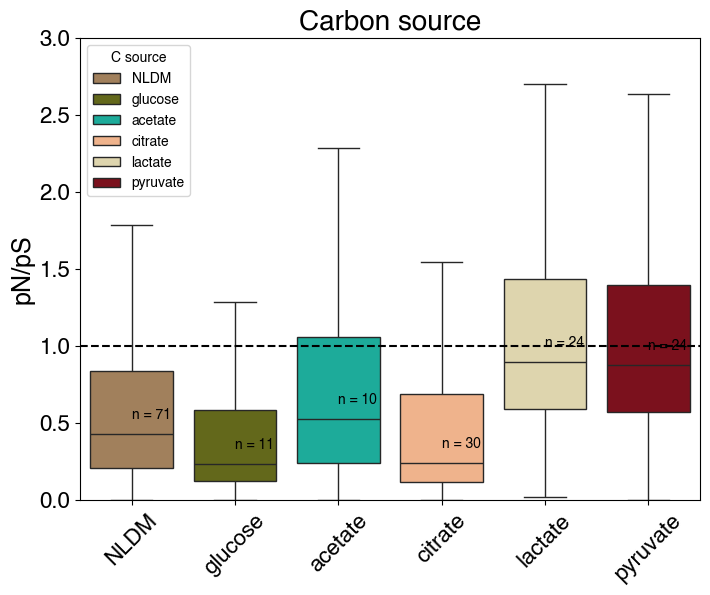

In [27]:
#Plot the pN/pS values for each C source (rather than combining all single C sources into one medium)

#sns.set_context('talk')
c_palette = {
    'acetate':'xkcd:turquoise',
    'glucose':'xkcd:olive',
    'citrate':'xkcd:peach',
    'pyruvate':'xkcd:crimson',
    'lactate':'xkcd:beige',
    'no C':'xkcd:grey', #I'm generally not showing the 'no C' results because this was intended to be a control, and the coverage is actually very low. The same could be for acetate, but we want to learn something
    'NLDM':'xkcd:light brown'
}

plt.figure(figsize=(8,6))
sns.boxplot(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']!='no C'].dropna(how='any'),x='C source',y='value',hue='C source',showfliers=False,palette=c_palette,legend=True)
plt.axhline(1,color='black',linestyle='--')
plt.ylim((0,3))
plt.title('Carbon source',fontsize=20)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('',fontsize=18)
plt.xticks(fontsize=16,rotation=45)
plt.yticks(fontsize=16)


print('Mean pN/pS:')
print(f'NLDM: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='NLDM'].value.mean():.2f}')
print(f'acetate: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='acetate'].value.mean():.2f}')
print(f'citrate: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='citrate'].value.mean():.2f}')
print(f'glucose: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='glucose'].value.mean():.2f}')
print(f'lactate: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='lactate'].value.mean():.2f}')
print(f'pyruvate: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='pyruvate'].value.mean():.2f}')
print(f'No C: {bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']=='no C'].value.mean():.2f}\n')

for c in c_palette.keys():
    if c != 'no C':
        samples = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']==c].dropna(how='any')['samples'].unique()
        #n_g_samples = []
        #for s in samples:
        #    n_g_samples.append(len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['samples']==s].dropna(how='any')['gene_callers_id'].unique()))

        #n_g_samples = pd.Series(n_g_samples)
        
        n_samples = len(samples)
        n_genes = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']==c].dropna(how='any')['gene_callers_id'].unique())
        n_obs = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']==c].dropna(how='any'))

        plt.text(c,bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source']==c].value.median()+.1,f'n = {int(n_samples)}',fontsize=10)

        print(c,':')
        print(f'n observations = {n_obs}')
        print(f'n genes = {n_genes}')
        #print(f'mean n genes per sample = {n_g_samples.mean()} +- {n_g_samples.std()}')
        print(f'n samples = {n_samples}\n')

#plt.savefig('../figs/fig4B_Csource.pdf',dpi=300,bbox_inches='tight')
plt.show()

NLDM T1 mean pN/pS = 0.72
NLDM T2 mean pN/pS = 0.67
NLDM Timepoint t-test p = 1.63e-19

SGW T1 mean pN/pS = 0.99
SGW T3 mean pN/pS = 0.89
SGW Timepoint t-test p = 8.74e-29
NLDM T1 :
n observations = 139847
n genes = 5826
n samples = 38

SGW T1 :
n observations = 116869
n genes = 5732
n samples = 60

NLDM T2 :
n observations = 129965
n genes = 5820
n samples = 33

SGW T2 :
n observations = 0
n genes = 0
n samples = 0

NLDM T3 :
n observations = 0
n genes = 0
n samples = 0

SGW T3 :
n observations = 59204
n genes = 5489
n samples = 53



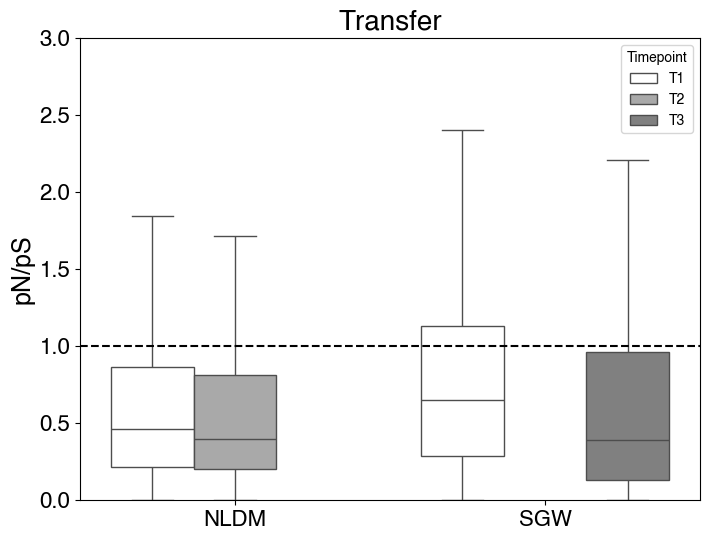

In [28]:
#Plot the changes in pN/pS over timepoints

plt.figure(figsize=(8,6))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='Media',y='value',hue='Timepoint',palette={'T1':'white','T2':'darkgray','T3':'gray'},showfliers=False,legend=True)
plt.ylim((0,3))
plt.title('Transfer',fontsize=20)
plt.axhline(1,color='black',linestyle='--')
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

b1_NLDM_T1_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['Timepoint'] == 'T1']['value']
b1_NLDM_T2_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['Timepoint'] == 'T2']['value']

b1_SGW_T1_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'SGW'].loc[bin_1_mean_pNpS_info_melt_df['Timepoint'] == 'T1']['value']
b1_SGW_T3_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'SGW'].loc[bin_1_mean_pNpS_info_melt_df['Timepoint'] == 'T3']['value']

b1_NLDM_time_t,b1_NLDM_time_p = ttest_ind(b1_NLDM_T1_pnps_vals,b1_NLDM_T2_pnps_vals,nan_policy='omit')
b1_SGW_time_t,b1_SGW_time_p = ttest_ind(b1_SGW_T1_pnps_vals,b1_SGW_T3_pnps_vals,nan_policy='omit')

print(f'NLDM T1 mean pN/pS = {b1_NLDM_T1_pnps_vals.mean():.2f}')
print(f'NLDM T2 mean pN/pS = {b1_NLDM_T2_pnps_vals.mean():.2f}')
print(f'NLDM Timepoint t-test p = {b1_NLDM_time_p:.2e}')
print('')
print(f'SGW T1 mean pN/pS = {b1_SGW_T1_pnps_vals.mean():.2f}')
print(f'SGW T3 mean pN/pS = {b1_SGW_T3_pnps_vals.mean():.2f}')
print(f'SGW Timepoint t-test p = {b1_SGW_time_p:.2e}')

for v in ['T1','T2','T3']:
    for m in ['NLDM','SGW']:
        samples = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['samples'].unique()
        
        n_samples = len(samples)
        n_genes = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['gene_callers_id'].unique())
        n_obs = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any'))

        #plt.text(v,bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].value.median()+.1,f'n = {int(n_samples)}',fontsize=10)

        print(m,v,':')
        print(f'n observations = {n_obs}')
        print(f'n genes = {n_genes}')
        print(f'n samples = {n_samples}\n')

#plt.savefig('../figs/fig4C_Transfers.pdf',dpi=300,bbox_inches='tight')
plt.show()

NLDM pH 4.5 mean pN/pS = 0.49
NLDM pH 6 mean pN/pS = 0.83
NLDM pH 7 mean pN/pS = 0.58

SGW pH 4.5 mean pN/pS = 1.11
SGW pH 7 mean pN/pS = 0.73

NLDM pH 4.5 vs 6 t-test p = 0.00e+00
NLDM pH 4.5 vs 7 t-test p = 2.65e-22
NLDM pH 6 vs 7 t-test p = 0.00e+00

SGW pH 4.5 vs 7 t-test p = 0.00e+00

NLDM vs SGW pH 4.5 t-test p = 0.00e+00
NLDM vs SGW pH 7 t-test p = 5.32e-83
NLDM 4.5 :
n observations = 32427
n genes = 5719
n samples = 14

SGW 4.5 :
n observations = 103987
n genes = 5699
n samples = 52

NLDM 6 :
n observations = 134174
n genes = 5817
n samples = 31

SGW 6 :
n observations = 0
n genes = 0
n samples = 0

NLDM 7 :
n observations = 103211
n genes = 5824
n samples = 26

SGW 7 :
n observations = 72086
n genes = 5624
n samples = 61



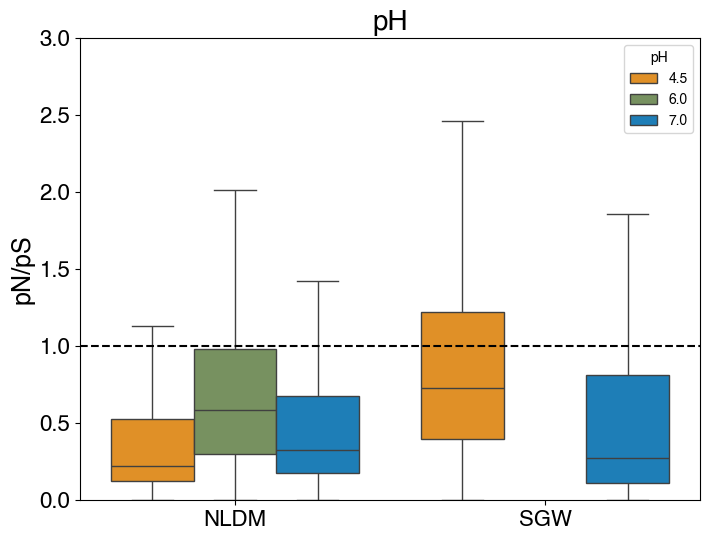

In [29]:
#Do another plot of the pH effect but separated by media this time
plt.figure(figsize=(8,6))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='Media',y='value',hue='pH',palette=pH_palette,showfliers=False,legend=True)
plt.ylim((0,3))
plt.title('pH',fontsize=20)
plt.axhline(1,color='black',linestyle='--')
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

#plt.savefig('./figs/fig6D_pH.pdf',dpi=300,bbox_inches='tight')
#plt.show()

b1_NLDM_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
b1_NLDM_pH6_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 6]['value']
b1_NLDM_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']

b1_SGW_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'SGW'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
b1_SGW_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media'] == 'SGW'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']

print(f'NLDM pH 4.5 mean pN/pS = {b1_NLDM_pH4_pnps_vals.mean():.2f}')
print(f'NLDM pH 6 mean pN/pS = {b1_NLDM_pH6_pnps_vals.mean():.2f}')
print(f'NLDM pH 7 mean pN/pS = {b1_NLDM_pH7_pnps_vals.mean():.2f}')
print('')
print(f'SGW pH 4.5 mean pN/pS = {b1_SGW_pH4_pnps_vals.mean():.2f}')
print(f'SGW pH 7 mean pN/pS = {b1_SGW_pH7_pnps_vals.mean():.2f}')
print('')

b1_NLDM_46_t,b1_NLDM_46_p = ttest_ind(b1_NLDM_pH4_pnps_vals,b1_NLDM_pH6_pnps_vals,nan_policy='omit')
b1_NLDM_47_t,b1_NLDM_47_p = ttest_ind(b1_NLDM_pH4_pnps_vals,b1_NLDM_pH7_pnps_vals,nan_policy='omit')
b1_NLDM_67_t,b1_NLDM_67_p = ttest_ind(b1_NLDM_pH6_pnps_vals,b1_NLDM_pH7_pnps_vals,nan_policy='omit')
b1_SGW_47_t,b1_SGW_47_p = ttest_ind(b1_SGW_pH4_pnps_vals,b1_SGW_pH7_pnps_vals,nan_policy='omit')
b1_NLDM_SGW_4_t,b1_NLDM_SGW_4_p = ttest_ind(b1_NLDM_pH4_pnps_vals,b1_SGW_pH4_pnps_vals,nan_policy='omit')
b1_NLDM_SGW_7_t,b1_NLDM_SGW_7_p = ttest_ind(b1_NLDM_pH7_pnps_vals,b1_SGW_pH7_pnps_vals,nan_policy='omit')

print(f'NLDM pH 4.5 vs 6 t-test p = {b1_NLDM_46_p:.2e}')
print(f'NLDM pH 4.5 vs 7 t-test p = {b1_NLDM_47_p:.2e}')
print(f'NLDM pH 6 vs 7 t-test p = {b1_NLDM_67_p:.2e}')
print('')
print(f'SGW pH 4.5 vs 7 t-test p = {b1_SGW_47_p:.2e}')
print('')
print(f'NLDM vs SGW pH 4.5 t-test p = {b1_NLDM_SGW_4_p:.2e}')
print(f'NLDM vs SGW pH 7 t-test p = {b1_NLDM_SGW_7_p:.2e}')

for v in pH_palette.keys():
    for m in ['NLDM','SGW']:
        samples = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['samples'].unique()
        
        n_samples = len(samples)
        n_genes = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['gene_callers_id'].unique())
        n_obs = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['pH']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any'))

        #plt.text(v,bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].value.median()+.1,f'n = {int(n_samples)}',fontsize=10)

        print(m,v,':')
        print(f'n observations = {n_obs}')
        print(f'n genes = {n_genes}')
        print(f'n samples = {n_samples}\n')

#plt.savefig('../figs/fig4C_pH.pdf',dpi=300,bbox_inches='tight')
plt.show()

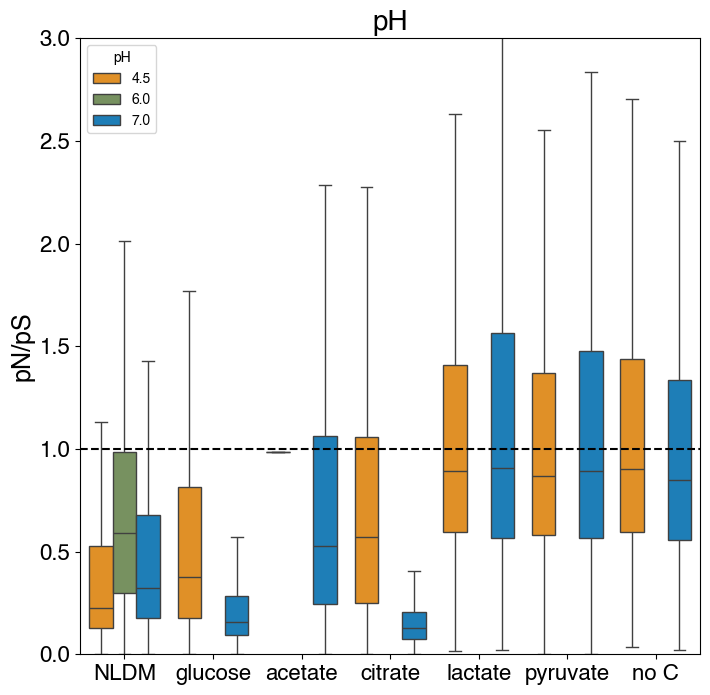

NLDM pH 4.5 vs 6 t-test p = 0.00e+00
NLDM pH 4.5 vs 7 t-test p = 2.65e-22
NLDM pH 6 vs 7 t-test p = 0.00e+00
glucose pH 4.5 vs 7 t-test p = 3.26e-122
acetate pH 4.5 vs 7 t-test p = 9.77e-01
citrate pH 4.5 vs 7 t-test p = 0.00e+00
lactate pH 4.5 vs 7 t-test p = 1.33e-16
pyruvate pH 4.5 vs 7 t-test p = 1.71e-09
no C pH 4.5 vs 7 t-test p = 1.51e-01


In [30]:
#Do another plot of the pH effect but separated by each carbon source this time; The pattern across C sources is fairly consistent, so we can go with the media as a whole for the comparison
plt.figure(figsize=(8,8))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='C source',y='value',hue='pH',palette=pH_palette,showfliers=False,legend=True)
plt.ylim((0,3))
plt.title('pH',fontsize=20)
plt.axhline(1,color='black',linestyle='--')
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

#plt.savefig('./figs/fig6D_pH.pdf',dpi=300,bbox_inches='tight')

plt.show()

NLDM_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
NLDM_pH6_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 6]['value']
NLDM_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'NLDM'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
NLDM_46_t,NLDM_46_p = ttest_ind(NLDM_pH4_pnps_vals,NLDM_pH6_pnps_vals,nan_policy='omit')
NLDM_47_t,NLDM_47_p = ttest_ind(NLDM_pH4_pnps_vals,NLDM_pH7_pnps_vals,nan_policy='omit')
NLDM_67_t,NLDM_67_p = ttest_ind(NLDM_pH6_pnps_vals,NLDM_pH7_pnps_vals,nan_policy='omit')
print(f'NLDM pH 4.5 vs 6 t-test p = {NLDM_46_p:.2e}')
print(f'NLDM pH 4.5 vs 7 t-test p = {NLDM_47_p:.2e}')
print(f'NLDM pH 6 vs 7 t-test p = {NLDM_67_p:.2e}')

glucose_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'glucose'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
glucose_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'glucose'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
glucose_t,glucose_p = ttest_ind(glucose_pH4_pnps_vals,glucose_pH7_pnps_vals,nan_policy='omit')
print(f'glucose pH 4.5 vs 7 t-test p = {glucose_p:.2e}')

acetate_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'acetate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
acetate_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'acetate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
acetate_t,acetate_p = ttest_ind(acetate_pH4_pnps_vals,acetate_pH7_pnps_vals,nan_policy='omit')
print(f'acetate pH 4.5 vs 7 t-test p = {acetate_p:.2e}')

citrate_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'citrate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
citrate_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'citrate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
citrate_t,citrate_p = ttest_ind(citrate_pH4_pnps_vals,citrate_pH7_pnps_vals,nan_policy='omit')
print(f'citrate pH 4.5 vs 7 t-test p = {citrate_p:.2e}')

lactate_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'lactate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
lactate_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'lactate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
lactate_t,lactate_p = ttest_ind(lactate_pH4_pnps_vals,lactate_pH7_pnps_vals,nan_policy='omit')
print(f'lactate pH 4.5 vs 7 t-test p = {lactate_p:.2e}')

pyruvate_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'pyruvate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
pyruvate_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'pyruvate'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
pyruvate_t,pyruvate_p = ttest_ind(pyruvate_pH4_pnps_vals,pyruvate_pH7_pnps_vals,nan_policy='omit')
print(f'pyruvate pH 4.5 vs 7 t-test p = {pyruvate_p:.2e}')

noC_pH4_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'no C'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 4.5]['value']
noC_pH7_pnps_vals = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == 'no C'].loc[bin_1_mean_pNpS_info_melt_df['pH'] == 7]['value']
noC_t,noC_p = ttest_ind(noC_pH4_pnps_vals,noC_pH7_pnps_vals,nan_policy='omit')
print(f'no C pH 4.5 vs 7 t-test p = {noC_p:.2e}')


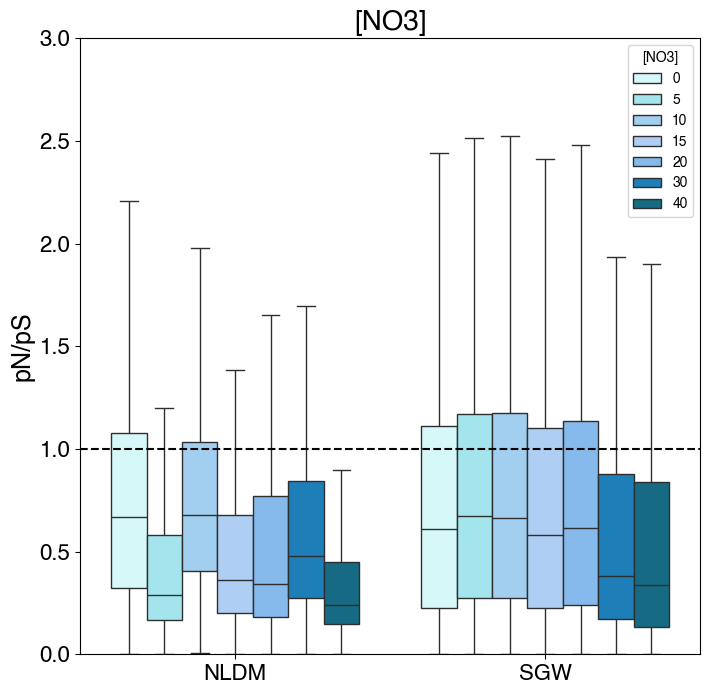

In [31]:
#Plot the differences in pN/pS by NO3- concentration in each medium
no3_palette = {0:'xkcd:pale blue',5:"xkcd:robin's egg blue",10:'xkcd:light blue',15:'xkcd:baby blue',20:'xkcd:sky blue',30:'xkcd:cerulean',40:'xkcd:sea blue'}

plt.figure(figsize=(8,8))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='Media',y='value',hue='[NO3]',palette=no3_palette,showfliers=False)
plt.axhline(1,color='black',linestyle='--')
plt.ylim((0,3))
#plt.yscale('log')
plt.title('[NO3]',fontsize=20)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#plt.savefig('../figs/fig6C_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

0 :
n observations = 116864
n genes = 5792
n samples = 44

5 :
n observations = 49120
n genes = 5750
n samples = 28

10 :
n observations = 45194
n genes = 5728
n samples = 18

15 :
n observations = 60365
n genes = 5750
n samples = 24

20 :
n observations = 67191
n genes = 5742
n samples = 25

30 :
n observations = 53020
n genes = 5783
n samples = 23

40 :
n observations = 54131
n genes = 5760
n samples = 22



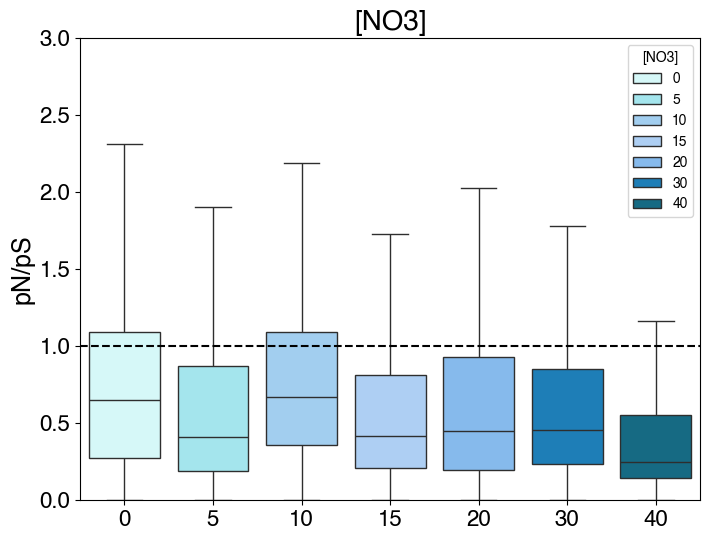

In [32]:
#Plot the differences in pN/pS by NO3- concentration across all samples
no3_palette = {0:'xkcd:pale blue',5:"xkcd:robin's egg blue",10:'xkcd:light blue',15:'xkcd:baby blue',20:'xkcd:sky blue',30:'xkcd:cerulean',40:'xkcd:sea blue'}

plt.figure(figsize=(8,6))
sns.boxplot(bin_1_mean_pNpS_info_melt_df,x='[NO3]',y='value',hue='[NO3]',palette=no3_palette,showfliers=False)
plt.axhline(1,color='black',linestyle='--')
plt.ylim((0,3))
#plt.yscale('log')
plt.title('[NO3]',fontsize=20)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

for v in no3_palette.keys():
    samples = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].dropna(how='any')['samples'].unique()
    
    n_samples = len(samples)
    n_genes = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].dropna(how='any')['gene_callers_id'].unique())
    n_obs = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].dropna(how='any'))

    #plt.text(v,bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].value.median()+.1,f'n = {int(n_samples)}',fontsize=10)

    print(v,':')
    print(f'n observations = {n_obs}')
    print(f'n genes = {n_genes}')
    print(f'n samples = {n_samples}\n')

#plt.savefig('../figs/fig4D_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

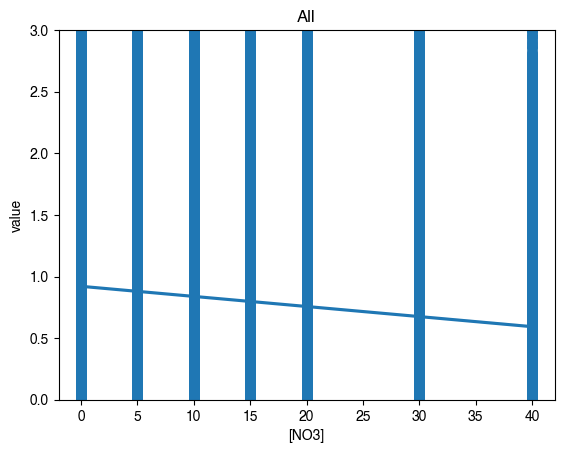

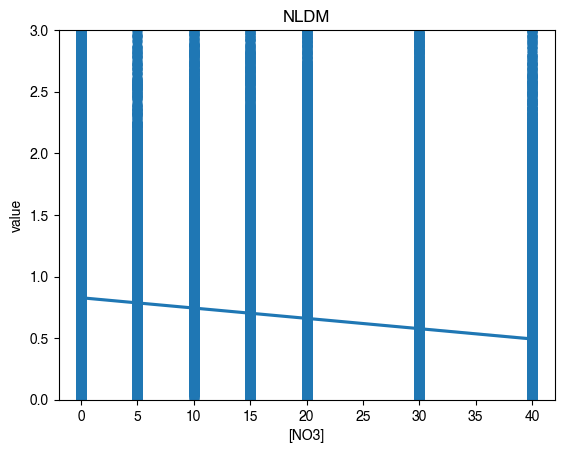

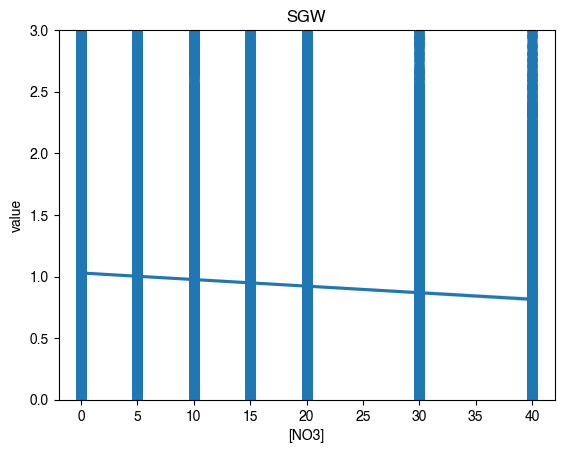

In [33]:
#Make some pretty gnarly plots of 
sns.regplot(bin_1_mean_pNpS_info_melt_df,x='[NO3]',y='value')
plt.title('All')
plt.ylim(0,3) #These are zoomed in so the trendline can be seen more easily, it looks a bit flat when you include the highest values
plt.show()

sns.regplot(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='NLDM'],x='[NO3]',y='value')
plt.title('NLDM')
plt.ylim(0,3)
plt.show()

sns.regplot(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='SGW'],x='[NO3]',y='value')
plt.title('SGW')
plt.ylim(0,3)
plt.show()


In [34]:
#Actually run and print the linear regression results for the NO3- concentrations across all samples
linregress(bin_1_mean_pNpS_info_melt_df['[NO3]'],
           bin_1_mean_pNpS_info_melt_df['value'],
           nan_policy='omit')

LinregressResult(slope=np.float64(-0.008188812133301705), intercept=np.float64(0.9205477858408261), rvalue=np.float64(-0.07005439760333793), pvalue=np.float64(0.0), stderr=np.float64(0.000174625132287113), intercept_stderr=np.float64(0.003513777421682858))

In [35]:
#Run and print the linear regression results for the NO3- concentrations across NLDM samples
linregress(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='NLDM']['[NO3]'],
           bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='NLDM']['value'],
           nan_policy='omit')

LinregressResult(slope=np.float64(-0.008363817007068793), intercept=np.float64(0.827750874499563), rvalue=np.float64(-0.08358126664371072), pvalue=np.float64(0.0), stderr=np.float64(0.00019197482314304207), intercept_stderr=np.float64(0.004073081804413622))

In [36]:
#Run and print the linear regression results for the NO3- concentrations across SGW samples
linregress(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='SGW']['[NO3]'],
           bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Media']=='SGW']['value'],
           nan_policy='omit')

LinregressResult(slope=np.float64(-0.005342101407818176), intercept=np.float64(1.0288733221864654), rvalue=np.float64(-0.037172950046561216), pvalue=np.float64(6.897174455849895e-55), stderr=np.float64(0.00034224799823279905), intercept_stderr=np.float64(0.006269106980496402))

In [37]:
#This is really not a good way to do it, but I ran pairwise t-tests on the concentrations. The linear regression results are more reliable
mean_pnps_no3_0 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 0]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_5 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 5]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_10 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 10]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_15 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 15]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_20 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 20]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_30 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 30]['value'].replace([np.inf, -np.inf], np.nan).mean()
mean_pnps_no3_40 = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == 40]['value'].replace([np.inf, -np.inf], np.nan).mean()

print(f'Mean pN/pS [NO3] = 0: {mean_pnps_no3_0:.2f}')
print(f'Mean pN/pS [NO3] = 5: {mean_pnps_no3_5:.2f}')
print(f'Mean pN/pS [NO3] = 10: {mean_pnps_no3_10:.2f}')
print(f'Mean pN/pS [NO3] = 15: {mean_pnps_no3_15:.2f}')
print(f'Mean pN/pS [NO3] = 20: {mean_pnps_no3_20:.2f}')
print(f'Mean pN/pS [NO3] = 30: {mean_pnps_no3_30:.2f}')
print(f'Mean pN/pS [NO3] = 40: {mean_pnps_no3_40:.2f}')

for i in [0,5,10,15,20,30,40]:
    for j in [0,5,10,15,20,30,40]:
        if i != j:
            stat,p = ttest_ind(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == i]['value'].replace([np.inf, -np.inf], np.nan),
                            bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]'] == j]['value'].replace([np.inf, -np.inf], np.nan),
                            nan_policy='omit')
            print(f'[NO3] = {i} vs. {j} : p = {p}')

Mean pN/pS [NO3] = 0: 0.93
Mean pN/pS [NO3] = 5: 0.74
Mean pN/pS [NO3] = 10: 0.96
Mean pN/pS [NO3] = 15: 0.73
Mean pN/pS [NO3] = 20: 0.81
Mean pN/pS [NO3] = 30: 0.75
Mean pN/pS [NO3] = 40: 0.52
[NO3] = 0 vs. 5 : p = 1.3978037236465517e-137
[NO3] = 0 vs. 10 : p = 0.0032575998409079955
[NO3] = 0 vs. 15 : p = 2.548325098187458e-161
[NO3] = 0 vs. 20 : p = 3.340183585795329e-59
[NO3] = 0 vs. 30 : p = 1.0433774815650808e-112
[NO3] = 0 vs. 40 : p = 0.0
[NO3] = 5 vs. 0 : p = 1.3978037236465517e-137
[NO3] = 5 vs. 10 : p = 2.8578447246565713e-148
[NO3] = 5 vs. 15 : p = 0.2012714925489486
[NO3] = 5 vs. 20 : p = 3.49915612096809e-18
[NO3] = 5 vs. 30 : p = 0.40046104569590874
[NO3] = 5 vs. 40 : p = 2.188721865370112e-99
[NO3] = 10 vs. 0 : p = 0.0032575998409079955
[NO3] = 10 vs. 5 : p = 2.8578447246565713e-148
[NO3] = 10 vs. 15 : p = 9.436804509711336e-148
[NO3] = 10 vs. 20 : p = 3.455623332680777e-58
[NO3] = 10 vs. 30 : p = 4.267087829748176e-101
[NO3] = 10 vs. 40 : p = 0.0
[NO3] = 15 vs. 0 : p = 

In [38]:
#Run pairwise t-tests between carbon sources
for i in c_palette.keys():
    for j in c_palette.keys():
        if i != j:
            stat,p = ttest_ind(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == i]['value'].replace([np.inf, -np.inf], np.nan),
                            bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['C source'] == j]['value'].replace([np.inf, -np.inf], np.nan),
                            nan_policy='omit')
            print(f'C = {i} vs. {j} : p = {p}')

C = acetate vs. glucose : p = 3.7366403211941343e-62
C = acetate vs. citrate : p = 9.667062677238872e-51
C = acetate vs. pyruvate : p = 4.847880669433809e-16
C = acetate vs. lactate : p = 2.918205613243083e-23
C = acetate vs. no C : p = 8.590676699052175e-16
C = acetate vs. NLDM : p = 8.91924474044032e-44
C = glucose vs. acetate : p = 3.7366403211941343e-62
C = glucose vs. citrate : p = 0.021481673223764895
C = glucose vs. pyruvate : p = 0.0
C = glucose vs. lactate : p = 0.0
C = glucose vs. no C : p = 0.0
C = glucose vs. NLDM : p = 3.282371279316949e-30
C = citrate vs. acetate : p = 9.667062677238872e-51
C = citrate vs. glucose : p = 0.021481673223764895
C = citrate vs. pyruvate : p = 0.0
C = citrate vs. lactate : p = 0.0
C = citrate vs. no C : p = 0.0
C = citrate vs. NLDM : p = 1.269825091559598e-37
C = pyruvate vs. acetate : p = 4.847880669433809e-16
C = pyruvate vs. glucose : p = 0.0
C = pyruvate vs. citrate : p = 0.0
C = pyruvate vs. lactate : p = 0.36450960635818924
C = pyruvate v

In [39]:
#Check through all of the genes for mean pN/pS for specific functions/genes
#The gene order is a little messy as is because the 'gene_callers_id' is not exactly linear or ordered here, range much greater than number of genes.
#Let's give each gene_callers_id a new id for ease of use.

b1_gene_id_dict = {}
id_num = 0
for g in bin_1_mean_pNpS_info_melt_df['gene_callers_id'].unique():
    b1_gene_id_dict[g] = id_num
    id_num += 1

bin_1_mean_pNpS_info_melt_df['gene_id'] = bin_1_mean_pNpS_info_melt_df['gene_callers_id'].map(b1_gene_id_dict)

In [40]:
#Gene names for C metabolism that can be found in KOfams, use to check pN/pS for these genes as essential background functions
glycolysis_gene_list = ['glucokinase','phosphoglucose isomerase','fructose-bisphosphate aldolase','phosphofructokinase','enolase','pyruvate kinase']
glyoxylate_cycle_gene_list = ['malate synthase','isocitrate lyase']

C_gene_KO_dict = {
    'glucokinase_1':'K00845',
    'glucokinase_2':'K25026',
    'phosphoglucose isomerase':'K01810',
    'fructose-bisphosphate aldolase':'K01624',
    'glyceraldehyde 3-phosphate dehydrogenase':'K00134',
    'phosphoglycerate kinase':'K00927',
    'phosphoglycerate mutase':'K01834',
    'phosphofructokinase':'K16370',
    'enolase':'K01689',
    'pyruvate kinase':'K00873',
    'malate synthase':'K01638',
    'isocitrate lyase':'K01637'
}

C_gene_calls_list = bin_1_gene_calls_df[bin_1_gene_calls_df['KOfam (ACCESSION)'].isin(C_gene_KO_dict.values())]['gene_callers_id'].to_list()
C_gene_calls_list

[32747,
 32880,
 33270,
 33296,
 33300,
 76537,
 137852,
 138112,
 138115,
 138450,
 138630,
 139901,
 140329,
 140452]

In [41]:
#This is to make a smaller df with just these C related genes with pN/pS info
#annotations
C_gene_KO_df = bin_1_gene_calls_df[bin_1_gene_calls_df['KOfam (ACCESSION)'].isin(C_gene_KO_dict.values())][['gene_callers_id','KEGG_Module','KOfam','KOfam (ACCESSION)']]
#merge with pN/pS info
bin_1_C_mean_pNpS_info_melt_df = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['gene_callers_id'].isin(C_gene_calls_list)].merge(C_gene_KO_df,how='left')
bin_1_C_mean_pNpS_info_melt_df

,gene_callers_id,samples,value,Timepoint,Media,pH,C source,[NO3],C_ID,gene_id,KEGG_Module,KOfam,KOfam (ACCESSION)
0,32747,NLDM_T1_A1,NaN,T1,NLDM,4.5,NLDM,0,6,441,"Glycolysis (Embden-Meyerhof pathway), glucose ...","fructose-bisphosphate aldolase, class II [EC:4...",K01624
1,32880,NLDM_T1_A1,NaN,T1,NLDM,4.5,NLDM,0,6,574,"Glycolysis (Embden-Meyerhof pathway), glucose ...",glucokinase [EC:2.7.1.2],K00845
2,33270,NLDM_T1_A1,NaN,T1,NLDM,4.5,NLDM,0,6,964,"Glycolysis (Embden-Meyerhof pathway), glucose ...",pyruvate kinase [EC:2.7.1.40],K00873
3,33296,NLDM_T1_A1,NaN,T1,NLDM,4.5,NLDM,0,6,990,"Glycolysis (Embden-Meyerhof pathway), glucose ...",phosphoglycerate kinase [EC:2.7.2.3],K00927
4,33300,NLDM_T1_A1,NaN,T1,NLDM,4.5,NLDM,0,6,994,"Glycolysis (Embden-Meyerhof pathway), glucose ...",glyceraldehyde 3-phosphate dehydrogenase (phos...,K00134
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4027,138450,SGW_T3_B7,NaN,T3,SGW,7.0,no C,40,0,3321,"Glycolysis (Embden-Meyerhof pathway), glucose ...",glucose-6-phosphate isomerase [EC:5.3.1.9],K01810
4028,138630,SGW_T3_B7,NaN,T3,SGW,7.0,no C,40,0,3501,Glyoxylate cycle,isocitrate lyase [EC:4.1.3.1],K01637
4029,139901,SGW_T3_B7,NaN,T3,SGW,7.0,no C,40,0,4772,"Glycolysis (Embden-Meyerhof pathway), glucose ...",enolase [EC:4.2.1.11],K01689
4030,140329,SGW_T3_B7,NaN,T3,SGW,7.0,no C,40,0,5200,"Glycolysis (Embden-Meyerhof pathway), glucose ...",pyruvate kinase [EC:2.7.1.40],K00873


In [42]:
#We also want to give the genes good IDs for these, so let's convert them from gene_callers_id -> KO -> gene name
denit_gene_KO_dict = {
    'K00370':'narG', #no3 red
    'K00371':'narH',
    'K00374':'narI',
    'K02575':'narK', #no3/no2 transporter
    'K02567':'napA', #no3 red
    'K02568':'napB',
    'K02569':'napC',
    'K02573':'napG',
    'K02574':'napH',
    'K00368':'nirK', #no2 red to NO
    'K15864':'nirS', #no2 red to NO
    'K04561':'norB', #NO red to N2O
    'K02305':'norC',
    'K00376':'nosZ', #N2O red to N2
    'K19339':'nosR',
    'K00362':'nirB', #DNRA; no2 to nh4
    'K00363':'nirD', 
    'K03385':'nrfA', #DNRA; no2 to nh4
    'K15876':'nrfH',
    'K02586':'nifD', #nitrogen fixation
    'K02591':'nifK',
    'K02588':'nirH',
    'K22896':'vnfD', #nitrogen fixation
    'K22897':'vnfK',
    'K22898':'vnfG',
    'K22899':'vnfH',
    'K00531':'anfG', #nitrogen fixation
    'K10535':'hao', #nitrification
    'K10944':'amoA', #nitrification
    'K10945':'amoB',
    'K10946':'amoC',
    'K20932':'hzs', #anammox, all three are hydrazine synthase subunits but the symbols are listed same as the KOs
    'K20933':'hzs',
    'K20934':'hzs',
    'K20935':'hdh' #anammox
}

In [43]:
#KO IDs for denitrification and DNRA from anvio metab definitions
#Denitrification KOs: 	 Nar/Nap: (K00370+K00371+K00374,K02567+K02568) NirK/NirS: (K00368,K15864) Nor: (K04561+K02305) NosZ: K00376
#DNRA KOs: 		 Nar/Nap: (K00370+K00371+K00374,K02567+K02568) Nif/Nrf: (K00362+K00363,K03385+K15876)

denitrification_KO_list = ['K00370','K00371','K00374','K02567','K02568','K02569','K02573','K02574','K00368','K15864','K04561','K02305','K00376','K19339']
DNRA_KO_list = ['K00362','K00363','K02575','K03385','K15876']

In [44]:
#Look at denitrification genes using the KO dict
b1_dnr_gene_KO_df = bin_1_gene_calls_df[bin_1_gene_calls_df['KOfam (ACCESSION)'].fillna('none').isin(denit_gene_KO_dict.keys())]

#Let's make another dict to link the gene_callers_id to these KOs to map them back to a new df later

b1_dnr_gene_KO_dict = dict(zip(b1_dnr_gene_KO_df['gene_callers_id'],b1_dnr_gene_KO_df['KOfam (ACCESSION)']))
b1_dnr_gene_KO_dict

{19590: 'K19339',
 19591: 'K00376',
 19648: 'K02567',
 19649: 'K02568',
 19650: 'K02569',
 32805: 'K19339',
 32806: 'K00376',
 41211: 'K02305',
 41212: 'K04561',
 93351: 'K02575',
 140564: 'K00368'}

In [45]:
#Create a list of genes that are involved in denitrification (at least according to KEGG) to subset the var_df
bin_1_dnr_genes = bin_1_gene_calls_df[bin_1_gene_calls_df['KOfam (ACCESSION)'].fillna('none').isin(denit_gene_KO_dict.keys())]['gene_callers_id'].to_list()

bin_1_dnr_var_df = bin_1_var_df[bin_1_var_df['corresponding_gene_call'].isin(bin_1_dnr_genes)]
bin_1_dnr_var_df

,entry_id,unique_pos_identifier,sample_id,corresponding_gene_call,codon_order_in_gene,codon_number,gene_length,gene_coverage,non_outlier_gene_coverage,non_outlier_gene_coverage_std,...,nS_consensus,pN_reference,pS_reference,nN_reference,nS_reference,pN_popular_consensus,pS_popular_consensus,nN_popular_consensus,nS_popular_consensus,pN/pS
56689,1304089,430954,NLDM_T1_C3,19590,4,5,2211,96.927182,94.744436,1.082730,...,1.000000,0.031579,0.042105,2.000000,1.000000,0.031579,0.042105,2.000000,1.000000,0.750000
56703,1304090,430955,NLDM_T1_C3,19590,8,9,2211,96.927182,94.744436,1.082730,...,0.000000,0.035088,NaN,3.000000,0.000000,0.035088,NaN,3.000000,0.000000,NaN
56716,588842,237285,NLDM_T1_B6,19590,9,10,2211,39.386251,39.163853,0.916019,...,0.333333,0.010135,0.243243,2.666667,0.333333,0.010135,0.243243,2.666667,0.333333,0.041667
56725,5436715,237285,NLDM_T2_C1,19590,9,10,2211,68.691090,68.860133,1.037104,...,0.333333,0.033088,0.176471,2.666667,0.333333,0.033088,0.176471,2.666667,0.333333,0.187500
56729,7557530,237285,NLDM_T2_D3,19590,9,10,2211,52.892809,52.075758,1.085868,...,0.333333,0.015306,0.183673,2.666667,0.333333,0.015306,0.183673,2.666667,0.333333,0.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14371917,1208058,411295,NLDM_T1_C1,140564,354,355,1134,51.403880,51.407374,0.842049,...,1.000000,0.020000,0.060000,2.000000,1.000000,0.020000,0.060000,2.000000,1.000000,0.333333
14371920,3177431,616561,NLDM_T1_D7,140564,355,356,1134,60.487654,60.854726,0.942522,...,0.333333,0.037500,0.000000,2.666667,0.333333,0.037500,0.000000,2.666667,0.333333,inf
14371924,9369782,616561,NLDM_T2_E4,140564,355,356,1134,119.619048,120.617558,1.831459,...,0.333333,0.038793,0.000000,2.666667,0.333333,0.038793,0.000000,2.666667,0.333333,inf
14371935,13950075,608965,SGW_T1_H8,140564,364,365,1134,49.671076,50.405726,1.821839,...,0.333333,0.038265,0.000000,2.666667,0.333333,0.038265,0.000000,2.666667,0.333333,inf


In [46]:
#Subset our mean pN/pS by gene df for just the DNR genes
bin_1_dnr_mean_pNpS_info_melt_df = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['gene_callers_id'].isin(bin_1_dnr_genes)]
bin_1_dnr_mean_pNpS_info_melt_df['KOfam (ACCESSION)'] = bin_1_dnr_mean_pNpS_info_melt_df['gene_callers_id'].map(b1_dnr_gene_KO_dict)
bin_1_dnr_mean_pNpS_info_melt_df['gene'] = bin_1_dnr_mean_pNpS_info_melt_df['KOfam (ACCESSION)'].map(denit_gene_KO_dict)

bin_1_dnr_mean_pNpS_info_melt_df = bin_1_dnr_mean_pNpS_info_melt_df.sort_values(by='gene')
bin_1_dnr_mean_pNpS_info_melt_df

,gene_callers_id,samples,value,Timepoint,Media,pH,C source,[NO3],C_ID,gene_id,KOfam (ACCESSION),gene
312536,19648,NLDM_T2_B2,NaN,T2,NLDM,4.5,NLDM,5,6,101,K02567,napA
1061201,19648,SGW_T1_D6,NaN,T1,SGW,4.5,no C,15,0,101,K02567,napA
731081,19648,SGW_T1_D7,NaN,T1,SGW,7.0,acetate,15,4,101,K02567,napA
1515116,19648,SGW_T3_H3,NaN,T3,SGW,4.5,pyruvate,0,1,101,K02567,napA
943301,19648,SGW_T1_A4,1.311572,T1,SGW,4.5,pyruvate,0,1,101,K02567,napA
...,...,...,...,...,...,...,...,...,...,...,...,...
955034,19591,SGW_T1_B4,0.673069,T1,SGW,4.5,pyruvate,5,1,44,K00376,nosZ
159209,19591,NLDM_T1_D5,0.713410,T1,NLDM,6.0,NLDM,20,6,44,K00376,nosZ
1302839,19591,SGW_T3_D12,NaN,T3,SGW,7.0,acetate,20,4,44,K00376,nosZ
955490,32806,SGW_T1_B4,1.858902,T1,SGW,4.5,pyruvate,5,1,500,K00376,nosZ


In [47]:
#This is a palette of genes to color the dentrification operons differently
denit_gene_pal = {
    'narG':'xkcd:taupe', #no3 red
    'narH':'xkcd:taupe',
    'narI':'xkcd:taupe',
    'narK':'xkcd:taupe',
    'napA':'xkcd:sand', #no3 red
    'napB':'xkcd:sand',
    'napC':'xkcd:sand',
    'napG':'xkcd:sand',
    'napH':'xkcd:sand',
    'nirK':'xkcd:beige', #no2 red to NO
    'nirS':'xkcd:beige', #no2 red to NO
    'norB':'xkcd:moss green', #NO red to N2O
    'norC':'xkcd:moss green',
    'nosZ':'xkcd:burnt orange', #N2O red to N2
    'nosR':'xkcd:burnt orange',
    'nirB':'xkcd:slate', #DNRA; no2 to nh4
    'nirD':'xkcd:slate', 
    'nrfA':'xkcd:steel blue', #DNRA; no2 to nh4
    'nrfH':'xkcd:steel blue'
}

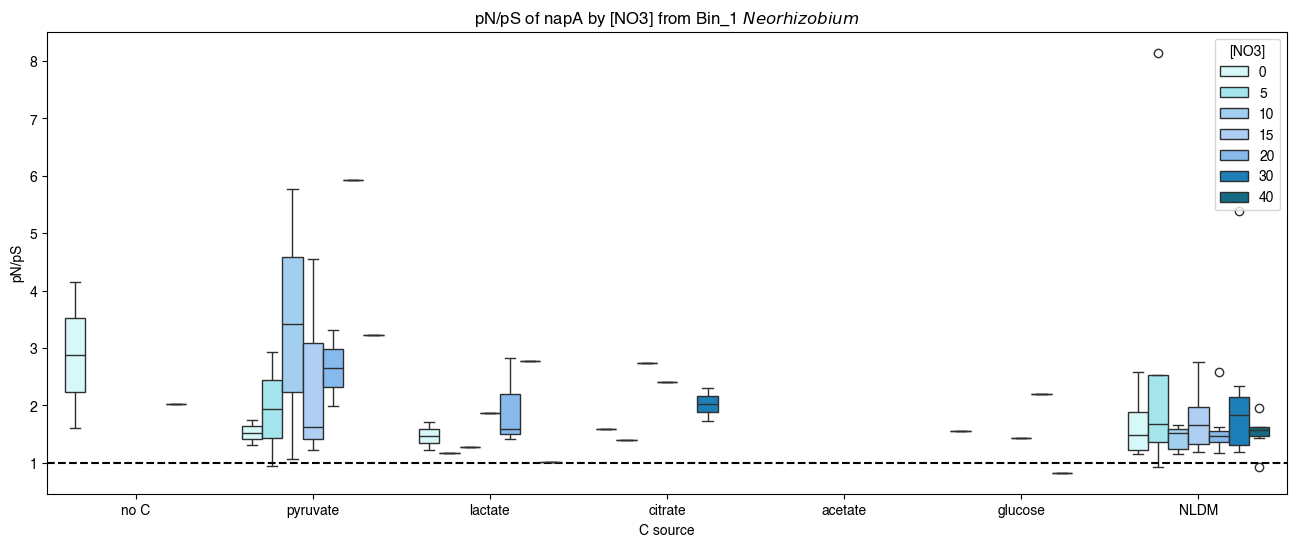

In [48]:
#Take a look at the pN/pS of napA by NO3 concentration for each different C source
plt.figure(figsize=(16,6))
sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].sort_values(by='C_ID'),x='C source',y='value',hue='[NO3]',palette=no3_palette)
plt.axhline(1,linestyle='--',color='black')
plt.title(r'pN/pS of napA by [NO3] from Bin_1 $\it{Neorhizobium}$')
plt.ylabel('pN/pS')
plt.show()

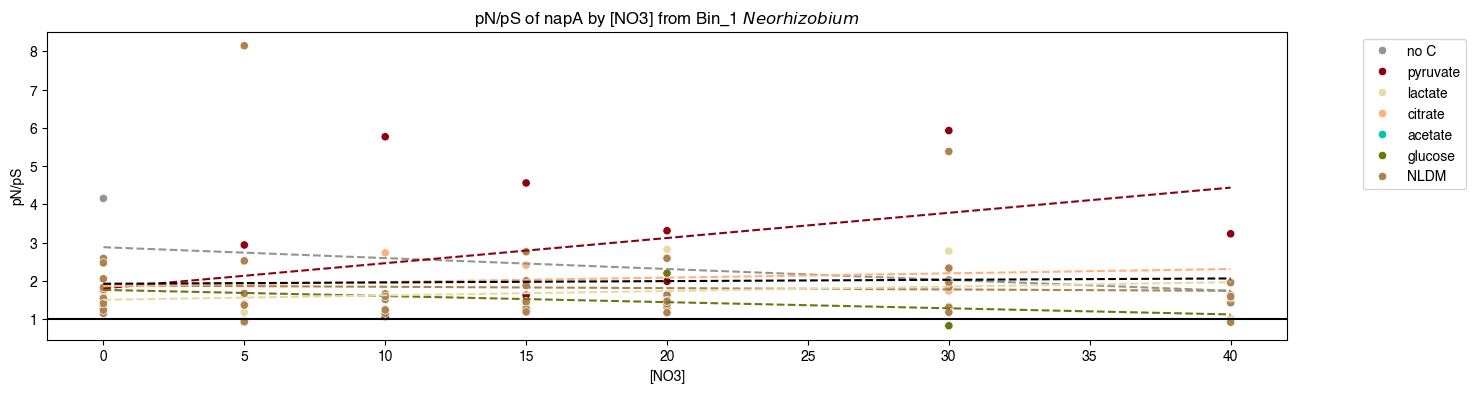

Overall: y = 0.00x + 1.93 | R^2 = 0.00 | p = 0.74
NLDM: y = -0.00x + 1.88 | R^2 = 0.00 | p = 0.78
no C: y = -0.03x + 2.88 | R^2 = 0.13 | p = 0.77
pyruvate: y = 0.07x + 1.80 | R^2 = 0.19 | p = 0.14
glucose: y = -0.02x + 1.77 | R^2 = 0.13 | p = 0.64
citrate: y = 0.01x + 1.86 | R^2 = 0.07 | p = 0.60
lactate: y = 0.01x + 1.51 | R^2 = 0.05 | p = 0.52


In [49]:
#Run linear regressions to check and see if any of the trends are significant with NO3 for any carbon source
#Spoiler: none of these are significant
no3_concs = np.array([0,5,10,15,20,30,40])

c_linregress_dict = {}
for c in bin_1_dnr_mean_pNpS_info_melt_df['C source'].unique(): #get the data (no nans) for each C source and run the test
    df = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].loc[bin_1_dnr_mean_pNpS_info_melt_df['C source']==c].dropna()
    x_series = df['[NO3]'] #[NO3] range list
    y_series = df['value'] #relative abundance data

    #Do the linear regression to create results objects for each C source
    if len(x_series) > 0:
        results = linregress(x=x_series,y=y_series)
    else:
        results = None
    #pval = results.pvalue
    #rval = results.rvalue
    #r2val = rval*rval
    #slope = results.slope
    #intercept = results.intercept
    c_linregress_dict[c] = results

#Run the regression over all data as well for a comparison
x_series_all = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].dropna()['[NO3]']
y_series_all = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].dropna()['value']
results_all = linregress(x=x_series_all,y=y_series_all)

plt.figure(figsize=(16,4))
sns.scatterplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].sort_values(by='C_ID'),x='[NO3]',y='value',hue='C source',palette=c_palette)

for c in bin_1_dnr_mean_pNpS_info_melt_df['C source'].unique():
    if c_linregress_dict[c] != None:
        plt.plot(no3_concs, c_linregress_dict[c].slope*no3_concs + c_linregress_dict[c].intercept,color=c_palette[c],ls='--')

plt.plot(no3_concs,results_all.slope*no3_concs + results_all.intercept, color='black',ls='--')
plt.axhline(1,linestyle='-',color='black')
plt.legend(bbox_to_anchor=(1.15,1))
plt.title(r'pN/pS of napA by [NO3] from Bin_1 $\it{Neorhizobium}$')
plt.ylabel('pN/pS')
plt.show()

print(f'Overall: y = {results_all.slope:.2f}x + {results_all.intercept:.2f} | R^2 = {results_all.rvalue * results_all.rvalue:.2f} | p = {results_all.pvalue:.2f}')
for c in c_linregress_dict.keys():
    if c_linregress_dict[c] != None:
        print(f'{c}: y = {c_linregress_dict[c].slope:.2f}x + {c_linregress_dict[c].intercept:.2f} | R^2 = {c_linregress_dict[c].rvalue * c_linregress_dict[c].rvalue:.2f} | p = {c_linregress_dict[c].pvalue:.2f}')

In [50]:
#Print the mean values for each concentration for napA and nirK
for c in no3_concs:
    print(f'{c} mM [NO3] mean napA pN/pS = {bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA'].loc[bin_1_dnr_mean_pNpS_info_melt_df['[NO3]']==c]['value'].mean():.2f}')
print('')
for c in no3_concs:
    print(f'{c} mM [NO3] mean nirK pN/pS = {bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK'].loc[bin_1_dnr_mean_pNpS_info_melt_df['[NO3]']==c]['value'].mean():.2f}')

0 mM [NO3] mean napA pN/pS = 1.74
5 mM [NO3] mean napA pN/pS = 2.34
10 mM [NO3] mean napA pN/pS = 2.00
15 mM [NO3] mean napA pN/pS = 1.97
20 mM [NO3] mean napA pN/pS = 1.88
30 mM [NO3] mean napA pN/pS = 2.38
40 mM [NO3] mean napA pN/pS = 1.67

0 mM [NO3] mean nirK pN/pS = 0.59
5 mM [NO3] mean nirK pN/pS = 0.56
10 mM [NO3] mean nirK pN/pS = 0.52
15 mM [NO3] mean nirK pN/pS = 0.45
20 mM [NO3] mean nirK pN/pS = 0.53
30 mM [NO3] mean nirK pN/pS = 0.38
40 mM [NO3] mean nirK pN/pS = 0.37


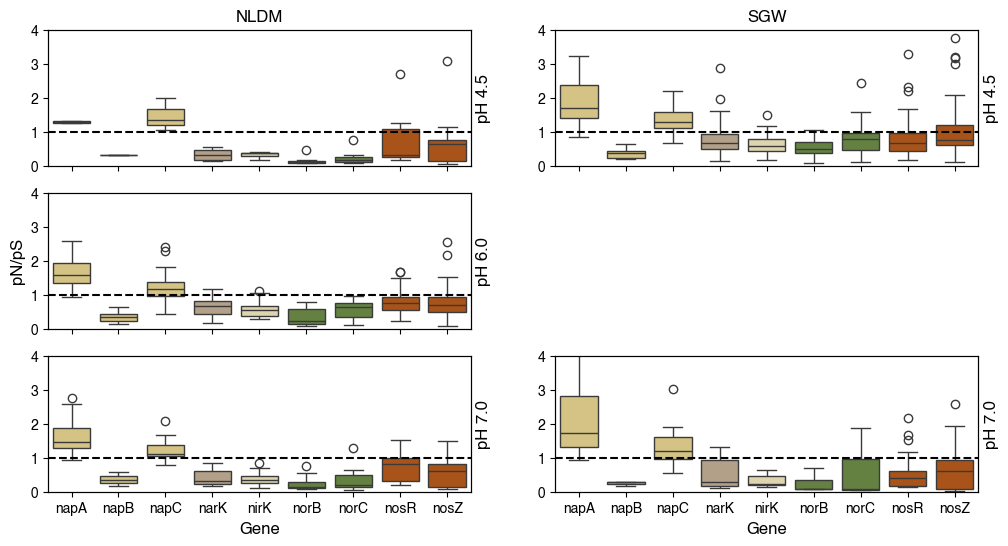

In [51]:
#Plot the mean pN/pS of each denitrification gene at each pH in NLDM and SGW. napA is consistently higher than the rest of the genes
fig,ax = plt.subplots(figsize=(12,6),nrows=3,ncols=2,sharex=True)
sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[0,0])
ax[0,0].axhline(1,linestyle='--',color='black')
ax[0,0].set_ylabel('')
ax0 = ax[0,0].twinx()
ax0.set_yticks([])
ax0.set_ylabel('pH 4.5',fontsize=12)
ax[0,0].set_title('NLDM')
#ax[0].set_yscale('log')
ax[0,0].set_ylim((0,4))

sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[1,0])
ax[1,0].axhline(1,linestyle='--',color='black')
ax[1,0].set_ylabel('pN/pS',fontsize=12)
ax1 = ax[1,0].twinx()
ax1.set_yticks([])
ax1.set_ylabel('pH 6.0',fontsize=12)
#ax[1].set_yscale('log')
ax[1,0].set_ylim((0,4))

sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[2,0])
ax[2,0].axhline(1,linestyle='--',color='black')
ax[2,0].set_ylabel('')
ax2 = ax[2,0].twinx()
ax2.set_yticks([])
ax2.set_ylabel('pH 7.0',fontsize=12)
ax[2,0].set_xlabel('Gene',fontsize=12)
#ax[2].set_yscale('log')
ax[2,0].set_ylim((0,4))

sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[0,1])
ax[0,1].axhline(1,linestyle='--',color='black')
ax[0,1].set_ylabel('')
ax0 = ax[0,1].twinx()
ax0.set_yticks([])
ax0.set_ylabel('pH 4.5',fontsize=12)
ax[0,1].set_title('SGW')
#ax[0].set_yscale('log')
ax[0,1].set_ylim((0,4))

#sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[1,1])
#ax[1,1].axhline(1,linestyle='--',color='black')
#ax[1,1].set_ylabel('pN/pS',fontsize=12)
#ax1 = ax[1,1].twinx()
#ax1.set_yticks([])
#ax1.set_ylabel('pH 6.0',fontsize=12)
#ax[1].set_yscale('log')
#ax[1,1].set_ylim((0,4))
ax[1,1].axis('off')


sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'],x='gene',y='value',hue='gene',palette=denit_gene_pal,ax=ax[2,1])
ax[2,1].axhline(1,linestyle='--',color='black')
ax[2,1].set_ylabel('')
ax2 = ax[2,1].twinx()
ax2.set_yticks([])
ax2.set_ylabel('pH 7.0',fontsize=12)
ax[2,1].set_xlabel('Gene',fontsize=12)
#ax[2].set_yscale('log')
ax[2,1].set_ylim((0,4))

plt.show()

In [52]:
#Run t-tests to look for significance of difference in NapA expression relative to other genes
b1_napA_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
#b1_napB_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napB']['value']
b1_nirK_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
#b1_norC_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norC']['value']
b1_nosZ_pH4_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==4.5].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

b1_napA_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
#b1_napB_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napB']['value']
b1_nirK_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
#b1_norC_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norC']['value']
b1_nosZ_pH6_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==6].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

b1_napA_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
#b1_napB_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napB']['value']
b1_nirK_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
#b1_norC_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norC']['value']
b1_nosZ_pH7_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['pH']==7].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

b1_napA_NLDM_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
b1_nirK_NLDM_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_NLDM_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
b1_nosZ_NLDM_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='NLDM'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

b1_napA_SGW_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
b1_nirK_SGW_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_SGW_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
b1_nosZ_SGW_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['Media']=='SGW'].loc[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

print('NapA mean pN/pS by pH')
print(b1_napA_pH4_pNpS.mean())
print(b1_napA_pH6_pNpS.mean())
print(b1_napA_pH7_pNpS.mean())
print(ttest_ind(b1_napA_pH4_pNpS,b1_napA_pH6_pNpS,nan_policy='omit'))
print(ttest_ind(b1_napA_pH4_pNpS,b1_napA_pH7_pNpS,nan_policy='omit'))
print(ttest_ind(b1_napA_pH6_pNpS,b1_napA_pH7_pNpS,nan_policy='omit'))
print('')
print('NapA mean pN/pS by Media')
print(b1_napA_NLDM_pNpS.mean())
print(b1_napA_SGW_pNpS.mean())
print(ttest_ind(b1_napA_NLDM_pNpS,b1_napA_SGW_pNpS,nan_policy='omit'))
print('')
print('All other gene means pH 4.5:')
print(b1_nirK_pH4_pNpS.mean())
print(b1_norB_pH4_pNpS.mean())
print(b1_nosZ_pH4_pNpS.mean())
print('')
print('All other gene means pH 6:')
print(b1_nirK_pH6_pNpS.mean())
print(b1_norB_pH6_pNpS.mean())
print(b1_nosZ_pH6_pNpS.mean())
print('')
print('All other gene means pH 7:')
print(b1_nirK_pH7_pNpS.mean())
print(b1_norB_pH7_pNpS.mean())
print(b1_nosZ_pH7_pNpS.mean())
print('')
print('All other gene means NLDM:')
print(b1_nirK_NLDM_pNpS.mean())
print(b1_norB_NLDM_pNpS.mean())
print(b1_nosZ_NLDM_pNpS.mean())
print('')
print('All other gene means SGW:')
print(b1_nirK_SGW_pNpS.mean())
print(b1_norB_SGW_pNpS.mean())
print(b1_nosZ_SGW_pNpS.mean())

NapA mean pN/pS by pH
2.13307808021766
2.0118197044724626
1.7977906441181888
TtestResult(statistic=np.float64(0.3217323581688846), pvalue=np.float64(0.7489209687837123), df=np.float64(53.0))
TtestResult(statistic=np.float64(1.1831395525440247), pvalue=np.float64(0.24184285007569611), df=np.float64(55.0))
TtestResult(statistic=np.float64(0.6845425094440547), pvalue=np.float64(0.49656029800751533), df=np.float64(54.0))

NapA mean pN/pS by Media
1.8263192668090866
2.1810533927622853
TtestResult(statistic=np.float64(-1.3346515543847064), pvalue=np.float64(0.18568453217822), df=np.float64(82.0))

All other gene means pH 4.5:
0.592698829140789
0.4131121624138122
1.125986633191362

All other gene means pH 6:
0.576696026672852
0.36118250429533844
0.7593139282149097

All other gene means pH 7:
0.37043326437115753
0.22877479614924023
0.619742580366955

All other gene means NLDM:
0.48450397093582903
0.28118555962694536
0.6872505433740604

All other gene means SGW:
0.5228005166168247
0.38556848821

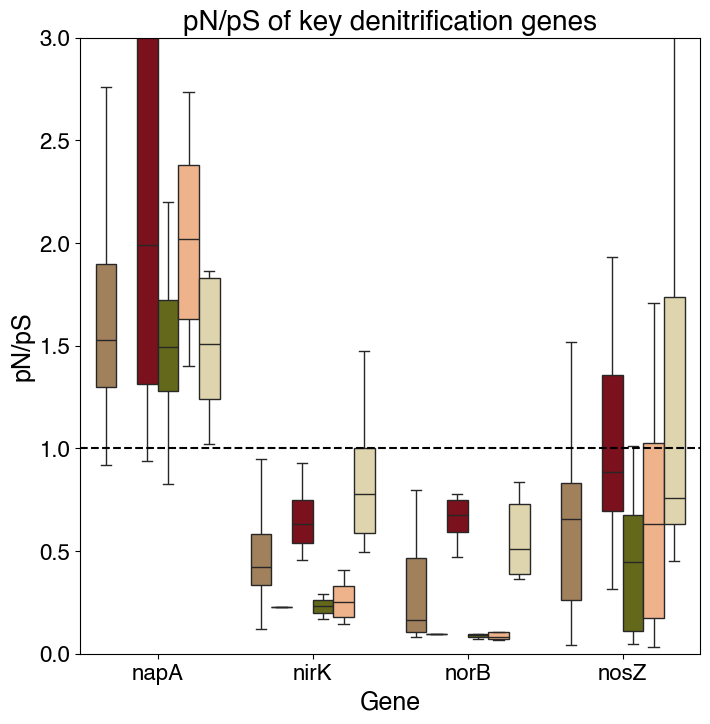

In [53]:
#Focus in on the key genes; check their pN/pS across all C sources
key_gene_list = ['napA', 'nirK', 'norB', 'nosZ']

plt.figure(figsize=(8,8))
sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene'].isin(key_gene_list)].loc[bin_1_dnr_mean_pNpS_info_melt_df['C source']!='no C'],x='gene',y='value',hue='C source',
            showfliers=False,palette=c_palette,legend=False)
plt.axhline(1,linestyle='--',color='black')
plt.ylabel('pN/pS',fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.xlabel('Gene',fontsize=18)
plt.title('pN/pS of key denitrification genes',fontsize=20)
#ax[0].set_yscale('log')
plt.ylim((0,3.0))

#plt.savefig('../figs/fig6F_pathway.pdf',dpi=300,bbox_inches='tight')

plt.show()

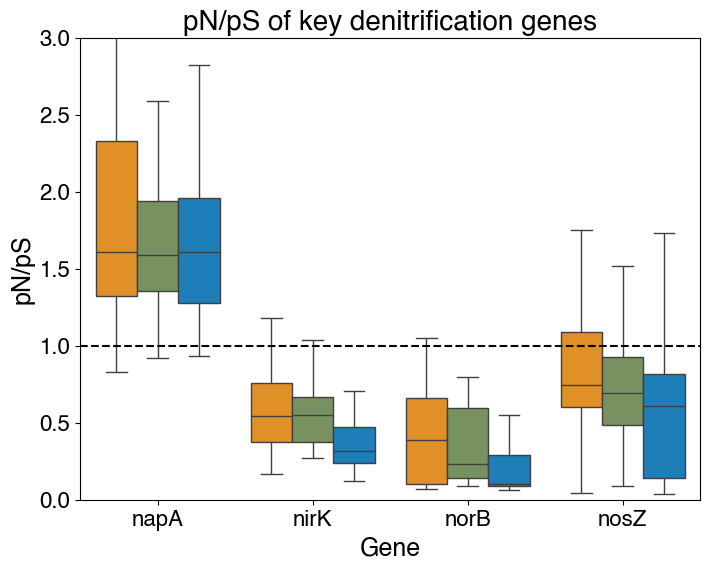

In [54]:
#Focus in on the key genes; check their pN/pS across all pHs

plt.figure(figsize=(8,6))
sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene'].isin(key_gene_list)],x='gene',y='value',hue='pH',showfliers=False,palette=pH_palette,legend=False)
plt.axhline(1,linestyle='--',color='black')
plt.ylabel('pN/pS',fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.xlabel('Gene',fontsize=18)
plt.title('pN/pS of key denitrification genes',fontsize=20)
#ax[0].set_yscale('log')
plt.ylim((0,3.0))

#plt.savefig('../figs/fig4_pH_pathway.pdf',dpi=300,bbox_inches='tight')

plt.show()

In [55]:
#Check linear regressions to see if any of the genes correlate significantly with pH
print('napA pH linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['pH'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value'],
           nan_policy='omit'))
           
print('nirK pH linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['pH'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value'],
           nan_policy='omit'))
           
print('norB pH linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['pH'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value'],
           nan_policy='omit'))
           
print('nosZ pH linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['pH'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value'],
           nan_policy='omit'))
           

napA pH linregress:
LinregressResult(slope=np.float64(-0.13040418674882615), intercept=np.float64(2.740591698094668), rvalue=np.float64(-0.11210971050386029), pvalue=np.float64(0.30995732184745195), stderr=np.float64(0.12764236646434857), intercept_stderr=np.float64(0.7577065819299115))
nirK pH linregress:
LinregressResult(slope=np.float64(-0.08797111406407697), intercept=np.float64(1.024804426375441), rvalue=np.float64(-0.3437051449895843), pvalue=np.float64(0.0020633656781206015), stderr=np.float64(0.02757076092685151), intercept_stderr=np.float64(0.16708053773425183))
norB pH linregress:
LinregressResult(slope=np.float64(-0.07232114502052106), intercept=np.float64(0.7526953298592339), rvalue=np.float64(-0.30022561716495944), pvalue=np.float64(0.0038353440849251456), stderr=np.float64(0.024356278032089916), intercept_stderr=np.float64(0.14603726442377))
nosZ pH linregress:
LinregressResult(slope=np.float64(-0.20573446086727915), intercept=np.float64(2.038532363591036), rvalue=np.floa

Mean pN/pS:
napA: 1.978348177931886
nirK: 0.49923341158236595
norB: 0.32592110045242284
nosZ: 0.8479101118539872

t-test results:
napA vs. nirK: TtestResult(statistic=np.float64(10.557201645257134), pvalue=np.float64(4.193411362526554e-20), df=np.float64(160.0))
napA vs. norB: TtestResult(statistic=np.float64(12.710949853124713), pvalue=np.float64(1.4480885712421231e-26), df=np.float64(173.0))
napA vs. nosZ: TtestResult(statistic=np.float64(8.38191237720724), pvalue=np.float64(2.6590847740833094e-15), df=np.float64(277.0))
0 :
n observations = 49453
n genes = 5667
n samples = 26

5 :
n observations = 22174
n genes = 5355
n samples = 19

10 :
n observations = 20533
n genes = 5478
n samples = 11

15 :
n observations = 21359
n genes = 5465
n samples = 14

20 :
n observations = 29723
n genes = 5512
n samples = 17

30 :
n observations = 18221
n genes = 5459
n samples = 13

40 :
n observations = 14610
n genes = 5414
n samples = 13



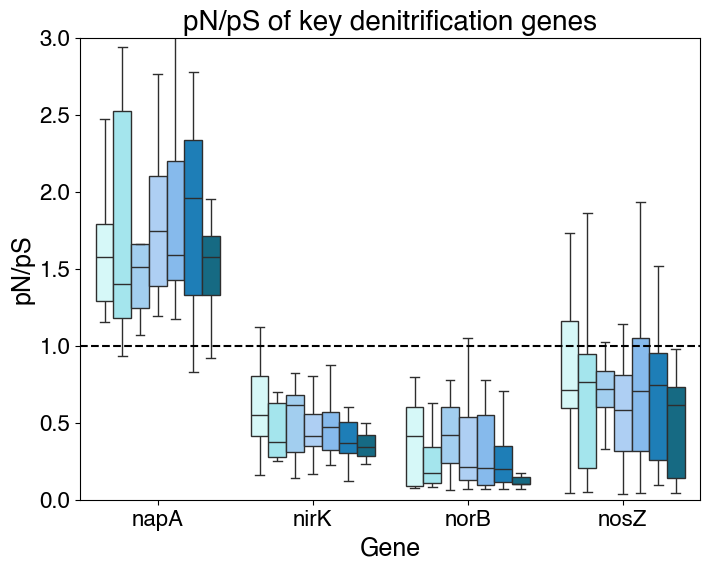

In [56]:
#Focus in on the key genes; check their pN/pS across all NO3 concentrations

plt.figure(figsize=(8,6))
sns.boxplot(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene'].isin(key_gene_list)],x='gene',y='value',hue='[NO3]',showfliers=False,palette=no3_palette,legend=False)
plt.axhline(1,linestyle='--',color='black')
plt.ylabel('pN/pS',fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.xlabel('Gene',fontsize=18)
plt.title('pN/pS of key denitrification genes',fontsize=20)
#ax[0].set_yscale('log')
plt.ylim((0,3.0))


#Run t-tests to look for significance of difference in NapA expression relative to other genes
b1_napA_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value']
b1_nirK_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value']
b1_norB_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value']
b1_nosZ_pNpS = bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value']

print('Mean pN/pS:')
print('napA:',b1_napA_pNpS.mean())
print('nirK:',b1_nirK_pNpS.mean())
print('norB:',b1_norB_pNpS.mean())
print('nosZ:',b1_nosZ_pNpS.mean())
print('')
print('t-test results:')
print('napA vs. nirK:',ttest_ind(b1_napA_pNpS,b1_nirK_pNpS,nan_policy='omit'))
print('napA vs. norB:',ttest_ind(b1_napA_pNpS,b1_norB_pNpS,nan_policy='omit'))
print('napA vs. nosZ:',ttest_ind(b1_napA_pNpS,b1_nosZ_pNpS,nan_policy='omit'))

for v in no3_palette.keys():
    samples = bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['samples'].unique()
    
    n_samples = len(samples)
    n_genes = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any')['gene_callers_id'].unique())
    n_obs = len(bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['[NO3]']==v].loc[bin_1_mean_pNpS_info_melt_df['Media']==m].dropna(how='any'))

    #plt.text(v,bin_1_mean_pNpS_info_melt_df[bin_1_mean_pNpS_info_melt_df['Timepoint']==v].value.median()+.1,f'n = {int(n_samples)}',fontsize=10)

    print(v,':')
    print(f'n observations = {n_obs}')
    print(f'n genes = {n_genes}')
    print(f'n samples = {n_samples}\n')

#plt.savefig('../figs/fig4E_dnr_pathway_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [57]:
#Check whether each gene correlates with NO3- concentration
#napA
print('napA NO3 linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['[NO3]'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='napA']['value'],
           nan_policy='omit'))
#nirK - SIGNIFICANT!
print('nirK NO3 linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['[NO3]'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nirK']['value'],
           nan_policy='omit')) 
#norB
print('norB NO3 linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['[NO3]'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='norB']['value'],
           nan_policy='omit'))
#nosZ
print('nosZ NO3 linregress:')
print(linregress(bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['[NO3]'],
           bin_1_dnr_mean_pNpS_info_melt_df[bin_1_dnr_mean_pNpS_info_melt_df['gene']=='nosZ']['value'],
           nan_policy='omit'))

napA NO3 linregress:
LinregressResult(slope=np.float64(0.003464814898568312), intercept=np.float64(1.9253447595430737), rvalue=np.float64(0.03697764288827052), pvalue=np.float64(0.738423462287494), stderr=np.float64(0.01034038643923332), intercept_stderr=np.float64(0.2065767876419602))
nirK NO3 linregress:
LinregressResult(slope=np.float64(-0.005614104738886571), intercept=np.float64(0.5830851041567614), rvalue=np.float64(-0.29775533018622574), pvalue=np.float64(0.008106795518026722), stderr=np.float64(0.0020646897719065137), intercept_stderr=np.float64(0.04196661764046092))
norB NO3 linregress:
LinregressResult(slope=np.float64(-0.003689281387949068), intercept=np.float64(0.3810576135030902), rvalue=np.float64(-0.19640293703721073), pvalue=np.float64(0.062057893911885466), stderr=np.float64(0.0019523456324110477), intercept_stderr=np.float64(0.03947366753721003))
nosZ NO3 linregress:
LinregressResult(slope=np.float64(-0.002474200806428643), intercept=np.float64(0.8844521545335488), rv

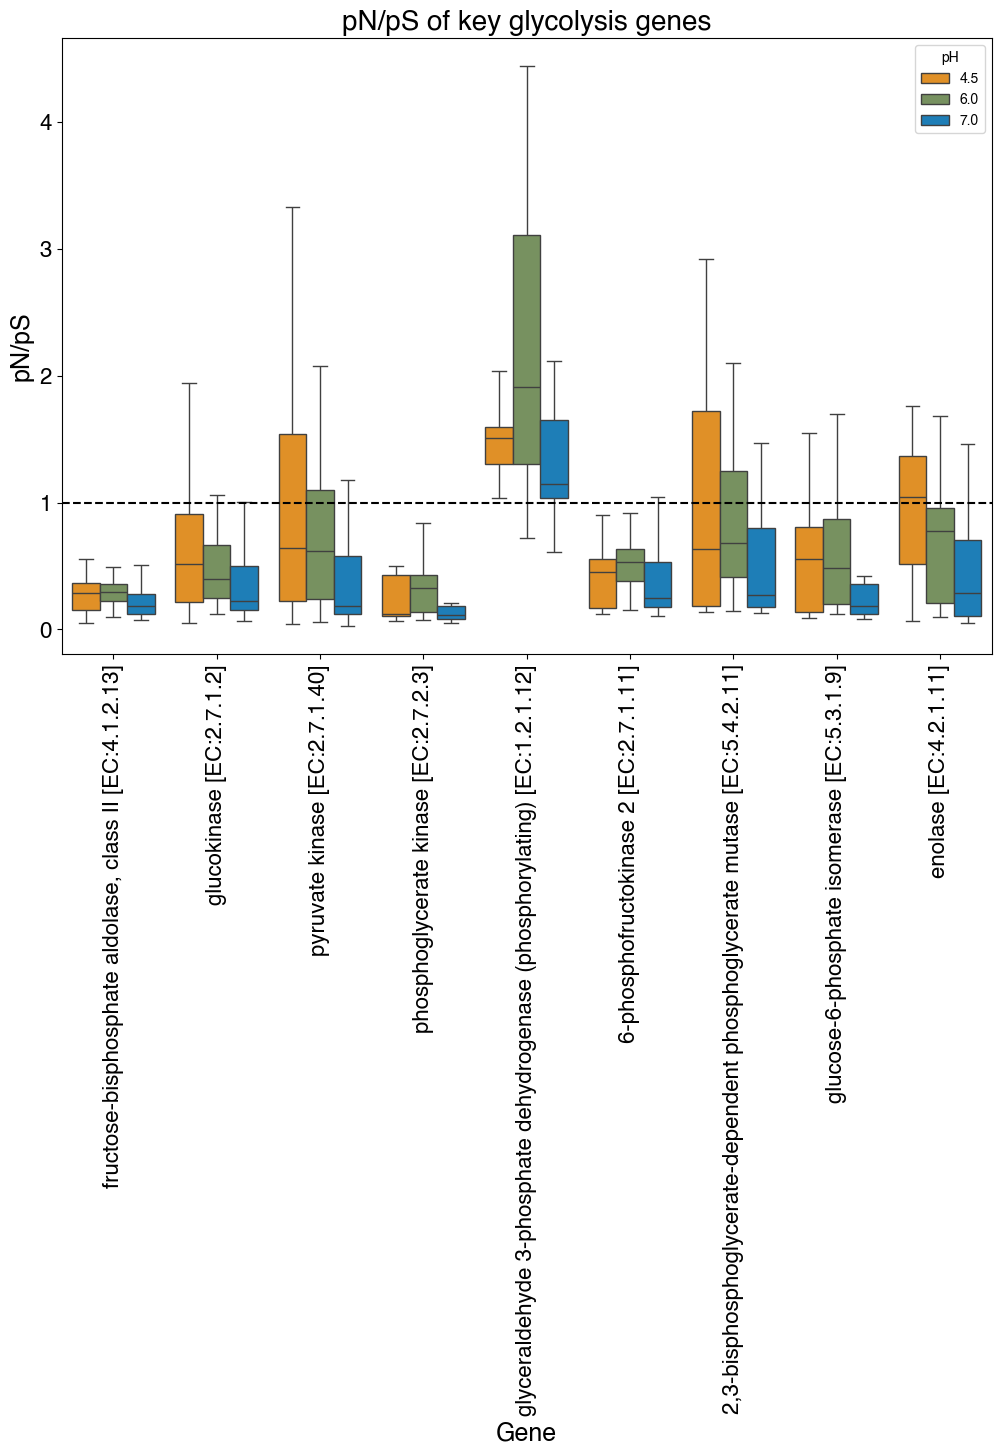

Mean pN/pS:
glucokinase: 0.7943290917406715
phosphofructokinase: 0.4328986878251363
enolase: 0.7386042279206877
pyruvate kinase: 0.8925394952184261

t-test results:
glucokinase vs. pyruvate kinase: TtestResult(statistic=np.float64(-0.7926493382577929), pvalue=np.float64(0.428389876247243), df=np.float64(461.0))
glucokinase vs. phosphofructokinase: TtestResult(statistic=np.float64(2.8192675773995215), pvalue=np.float64(0.0050660174457391755), df=np.float64(379.0))
glucokinase vs. enolase: TtestResult(statistic=np.float64(0.4073375033043377), pvalue=np.float64(0.6839944171643922), df=np.float64(372.0))
glucokinase pH 4.5 vs. 6: TtestResult(statistic=np.float64(0.9839931959563015), pvalue=np.float64(0.32653383715214657), df=np.float64(168.0))
glucokinase pH 4.5 vs. 7: TtestResult(statistic=np.float64(1.5552971137969869), pvalue=np.float64(0.12149680372284796), df=np.float64(195.0))
glucokinase pH 6 vs. 7: TtestResult(statistic=np.float64(0.6433386864202691), pvalue=np.float64(0.5208185968

In [58]:
#Make some plots and measurements to see if any of the carbon metabolism genes vary with pH
plt.figure(figsize=(12,8))
sns.boxplot(bin_1_C_mean_pNpS_info_melt_df.loc[bin_1_C_mean_pNpS_info_melt_df['KEGG_Module'].str.contains('Glycolysis')],x='KOfam',y='value',hue='pH',showfliers=False,palette=pH_palette)
plt.axhline(1,linestyle='--',color='black')
plt.ylabel('pN/pS',fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16,rotation=90)
plt.xlabel('Gene',fontsize=18)
plt.title('pN/pS of key glycolysis genes',fontsize=20)


plt.show()

#Run t-tests to look for significance of difference in NapA expression relative to other genes
glk_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')]['value']
pyr_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('pyruvate kinase')]['value']
pho_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('phosphofructokinase')]['value']
eno_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('enolase')]['value']

glk_4_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')].loc[bin_1_C_mean_pNpS_info_melt_df['pH']==4.5]['value']
glk_6_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')].loc[bin_1_C_mean_pNpS_info_melt_df['pH']==6]['value']
glk_7_pNpS = bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')].loc[bin_1_C_mean_pNpS_info_melt_df['pH']==7]['value']


print('Mean pN/pS:')
print('glucokinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')]['value'].mean())
print('phosphofructokinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('phosphofructokinase')]['value'].mean())
print('enolase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('enolase')]['value'].mean())
print('pyruvate kinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('pyruvate kinase')]['value'].mean())


print('')
print('t-test results:')

print('glucokinase vs. pyruvate kinase:',ttest_ind(glk_pNpS,pyr_pNpS,nan_policy='omit'))
print('glucokinase vs. phosphofructokinase:',ttest_ind(glk_pNpS,pho_pNpS,nan_policy='omit'))
print('glucokinase vs. enolase:',ttest_ind(glk_pNpS,eno_pNpS,nan_policy='omit'))

print('glucokinase pH 4.5 vs. 6:',ttest_ind(glk_4_pNpS,glk_6_pNpS,nan_policy='omit'))
print('glucokinase pH 4.5 vs. 7:',ttest_ind(glk_4_pNpS,glk_7_pNpS,nan_policy='omit'))
print('glucokinase pH 6 vs. 7:',ttest_ind(glk_6_pNpS,glk_7_pNpS,nan_policy='omit'))



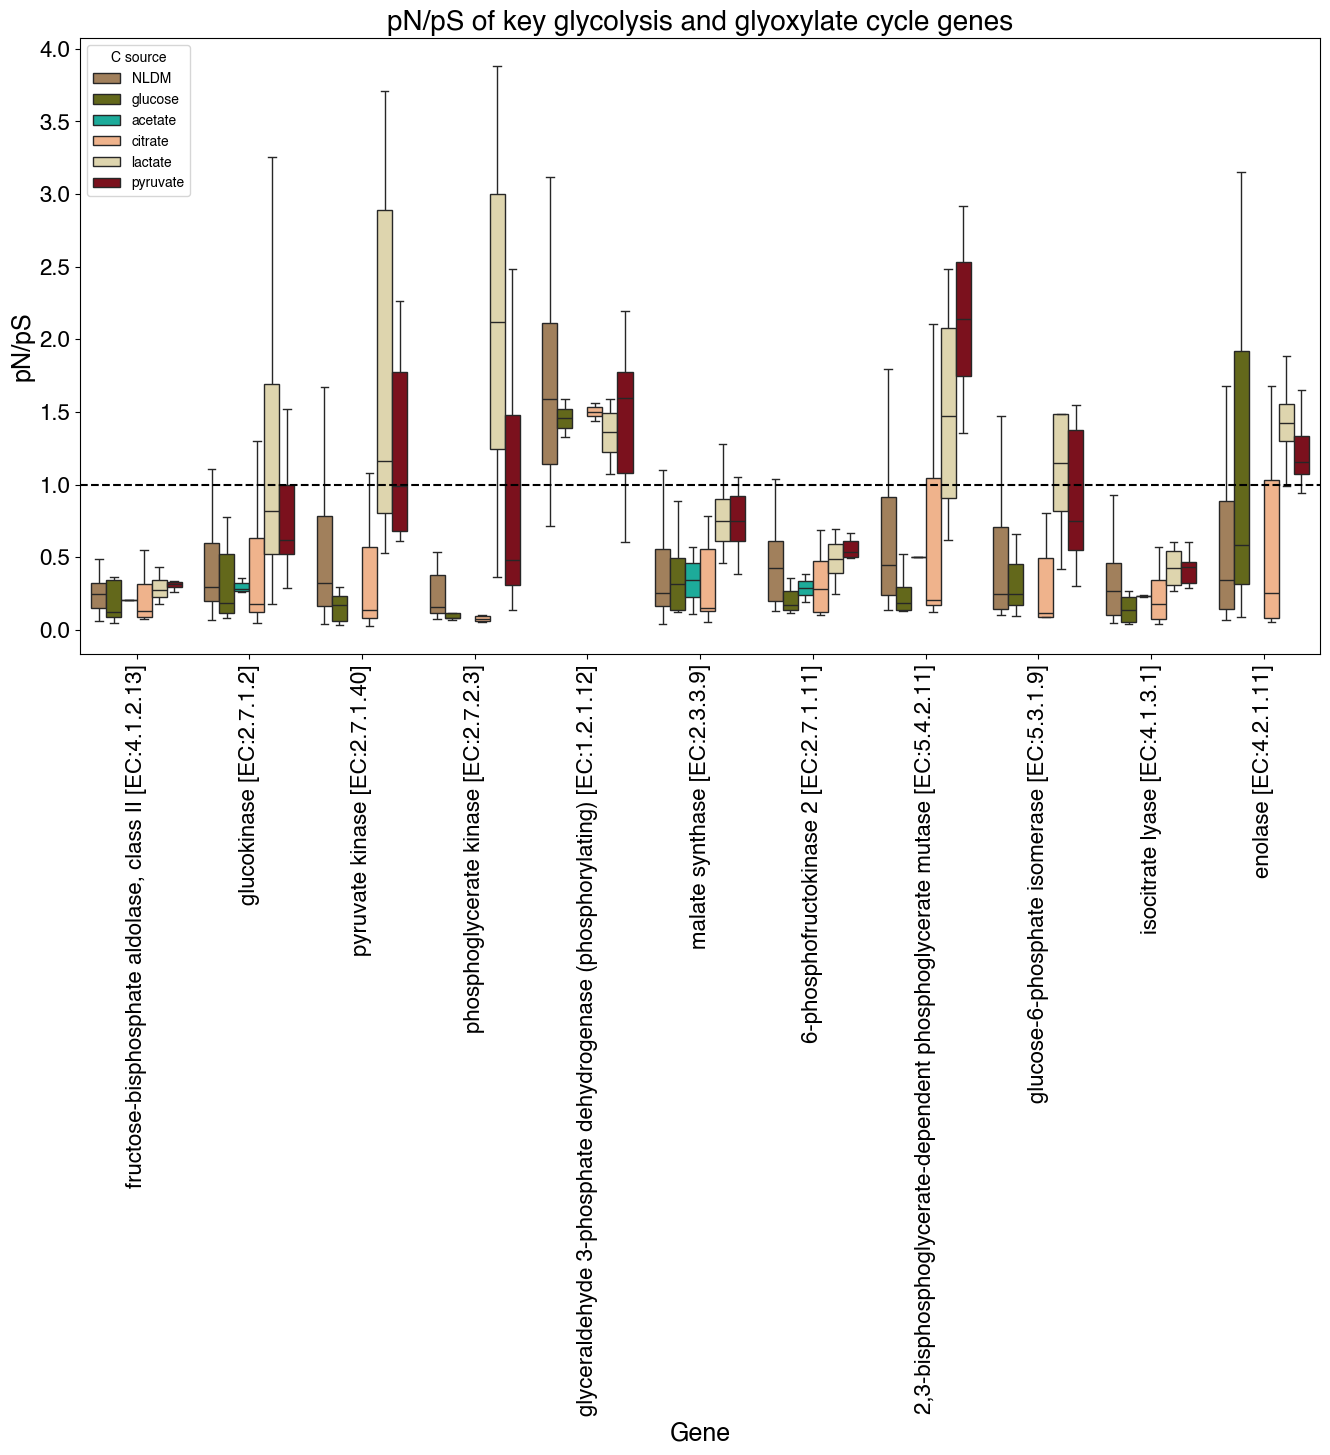

Mean pN/pS:
glucokinase: 0.7150515402592781
phosphofructokinase: 0.42856076040724056
enolase: 0.7169893592353617
pyruvate kinase: 0.8677649882505717

t-test results:


In [59]:
#Make some plots and measurements to see if any of the carbon metabolism genes vary with C source
plt.figure(figsize=(16,8))
sns.boxplot(bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['C source']!='no C'],x='KOfam',y='value',hue='C source',showfliers=False,palette=c_palette)
plt.axhline(1,linestyle='--',color='black')
plt.ylabel('pN/pS',fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16,rotation=90)
plt.xlabel('Gene',fontsize=18)
plt.title('pN/pS of key glycolysis and glyoxylate cycle genes',fontsize=20)

plt.show()

print('Mean pN/pS:')
print('glucokinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('glucokinase')].loc[bin_1_C_mean_pNpS_info_melt_df['C source']!='no C']['value'].mean())
print('phosphofructokinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('phosphofructokinase')].loc[bin_1_C_mean_pNpS_info_melt_df['C source']!='no C']['value'].mean())
print('enolase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('enolase')].loc[bin_1_C_mean_pNpS_info_melt_df['C source']!='no C']['value'].mean())
print('pyruvate kinase:',bin_1_C_mean_pNpS_info_melt_df[bin_1_C_mean_pNpS_info_melt_df['KOfam'].str.contains('pyruvate kinase')].loc[bin_1_C_mean_pNpS_info_melt_df['C source']!='no C']['value'].mean())

print('')
print('t-test results:')


In [60]:
#Identify a handful of genes to inspect at the codon level
bin_1_gene_calls_df[bin_1_gene_calls_df['gene_callers_id']==19648] #napA

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
101,19648,contig_953,94342,96847,f,Pathway modules; Energy metabolism; Nitrogen m...,M00530!!!M00529,"Dissimilatory nitrate reduction, nitrate => am...",M00530!!!M00529,Energy production and conversion,C,nitrate reductase (cytochrome) [EC:1.9.6.1],K02567,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko01000,Anaerobic selenocysteine-containing dehydrogen...,COG0243,ATGAAGGGAGAACTGACGCGGCGTGATCTCATCAAGGCGCATGCGG...


In [61]:
bin_1_gene_calls_df[bin_1_gene_calls_df['gene_callers_id']==140564] #nirK

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
5437,140564,contig_3,2970677,2971811,r,Pathway modules; Energy metabolism; Nitrogen m...,M00529!!!M00973,"Denitrification, nitrate => nitrogen!!!Anammox...",M00529!!!M00973,"Cell cycle control, cell division, chromosome ...",D!!!P!!!M,nitrite reductase (NO-forming) [EC:1.7.2.1],K00368,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko01000,Multicopper oxidase with three cupredoxin doma...,COG2132,ATGACTGACAAATTGCAGATGACCAGACGCTCGATTTTGGCAGGGG...


In [62]:
bin_1_gene_calls_df[bin_1_gene_calls_df['gene_callers_id']==32806] #nosZ

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
500,32806,contig_8,266951,268871,f,Pathway modules; Energy metabolism; Nitrogen m...,M00529,"Denitrification, nitrate => nitrogen",M00529,Inorganic ion transport and metabolism,P,nitrous-oxide reductase [EC:1.7.2.4],K00376,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko01000,Nitrous oxide reductase (NosZ) (PDB:1FWX),COG4263,ATGTCTGACGAACACAACCCACCGCGCCTGAACAGGCGGCAGATAC...


In [63]:
#Let's add sample metadata to our df so that we can label codon level data by NO3 or pH or C
bin_1_var_info_df = bin_1_var_df.merge(sample_info_df.rename({'samples':'sample_id'},axis=1),how='left',on='sample_id')
bin_1_var_info_df

,entry_id,unique_pos_identifier,sample_id,corresponding_gene_call,codon_order_in_gene,codon_number,gene_length,gene_coverage,non_outlier_gene_coverage,non_outlier_gene_coverage_std,...,pS_popular_consensus,nN_popular_consensus,nS_popular_consensus,pN/pS,Timepoint,Media,pH,C source,[NO3],C_ID
0,2533374,547094,NLDM_T1_D4,19547,2,3,1203,195.804655,193.893953,17.919387,...,0.063291,2.0,1.0,0.350000,T1,NLDM,6.0,NLDM,15,6
1,4203919,547094,NLDM_T1_E5,19547,2,3,1203,107.372402,107.224456,10.939680,...,0.034884,2.0,1.0,0.500000,T1,NLDM,7.0,NLDM,20,6
2,5640497,547094,NLDM_T2_C2,19547,2,3,1203,54.139651,54.798913,3.083288,...,0.043478,2.0,1.0,1.000000,T2,NLDM,6.0,NLDM,5,6
3,9144081,547094,NLDM_T2_E4,19547,2,3,1203,69.097257,69.097257,8.790138,...,0.035714,2.0,1.0,1.250000,T2,NLDM,7.0,NLDM,15,6
4,13003930,547094,SGW_T1_F3,19547,2,3,1203,149.663342,152.355901,13.316355,...,0.025424,2.0,1.0,1.666667,T1,SGW,4.5,citrate,30,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10290136,1439211,414201,NLDM_T1_C3,141023,265,266,801,68.484395,67.688742,1.048085,...,0.050000,2.0,1.0,1.000000,T1,NLDM,6.0,NLDM,10,6
10290137,2086008,414201,NLDM_T1_C7,141023,265,266,801,69.515605,71.969156,3.021141,...,0.017241,2.0,1.0,2.000000,T1,NLDM,6.0,NLDM,40,6
10290138,5326438,672088,NLDM_T1_F6,141023,266,267,801,20.716604,20.621039,3.286430,...,NaN,0.0,0.0,NaN,T1,NLDM,7.0,NLDM,30,6
10290139,6434165,672088,NLDM_T2_C4,141023,266,267,801,46.632959,46.632959,3.134140,...,NaN,0.0,0.0,NaN,T2,NLDM,6.0,NLDM,15,6


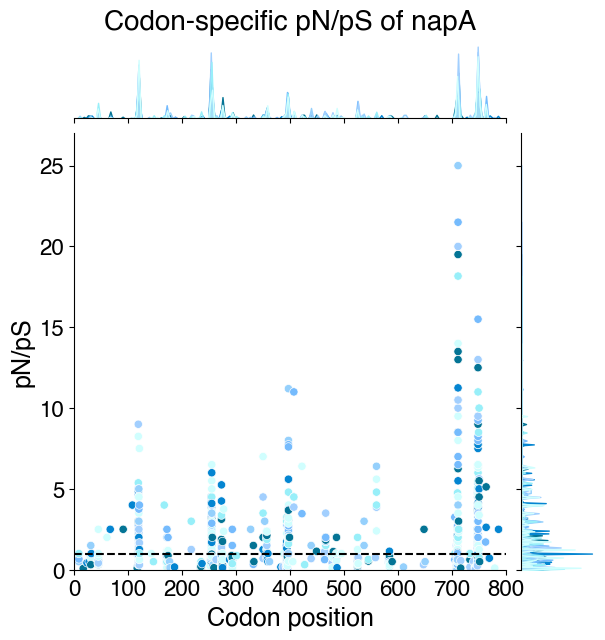

In [64]:
#Plot the pN/pS for each codon at different NO3 concentrations

#Set up a jointplot so that we can see the distribution of values across the gene for each concentration
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 19648],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.xlim(0,800)
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of napA',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#plt.savefig('../figs/fig4F_napA_pnps_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

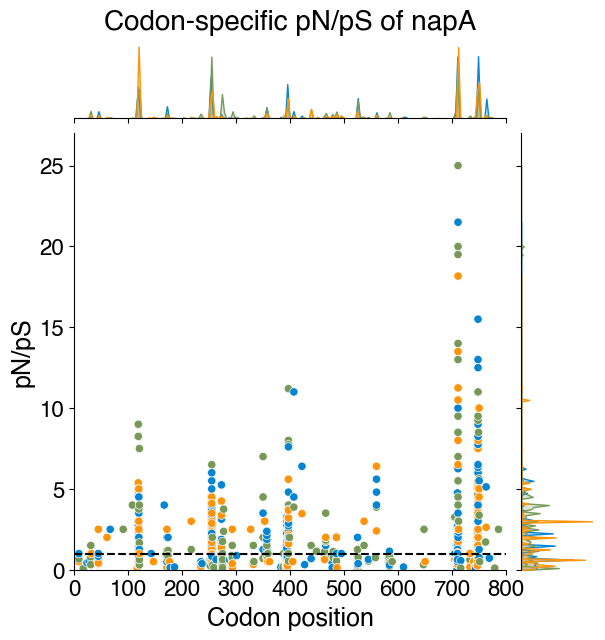

In [65]:
#Plot the pN/pS for each codon at different pH

#Set up a jointplot so that we can see the distribution of values across the gene for each pH
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 19648],x='codon_order_in_gene',y='pN/pS',hue='pH',palette=pH_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.xlim(0,800)
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of napA',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#plt.savefig('../figs/fig4F_napA_pnps_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

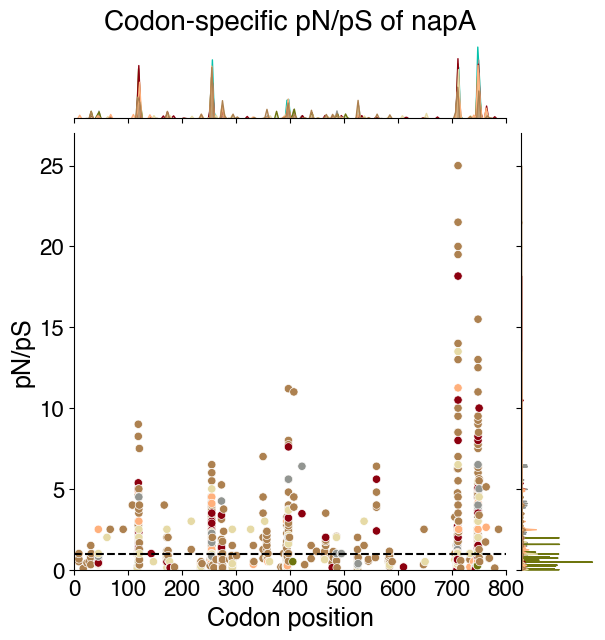

In [66]:
#Plot the pN/pS for each codon for different C sources

#Set up a jointplot so that we can see the distribution of values across the gene for each C source
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 19648],x='codon_order_in_gene',y='pN/pS',hue='C source',palette=c_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.xlim(0,800)
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of napA',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

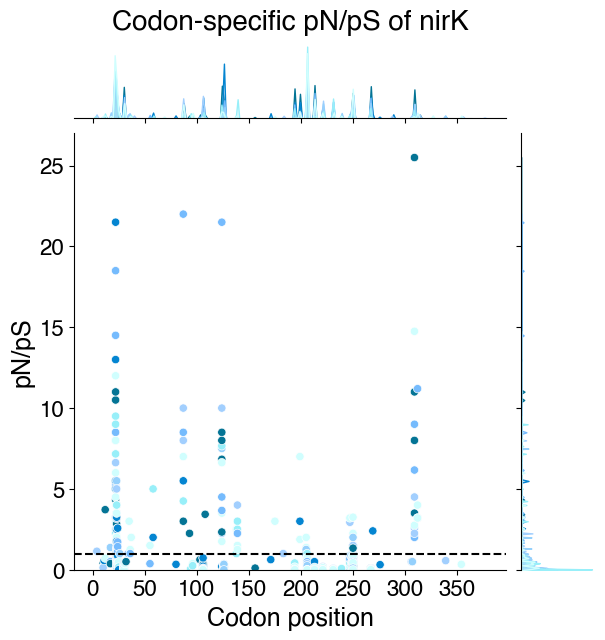

In [67]:
#Check the plots for nirK

g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 140564],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nirK',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

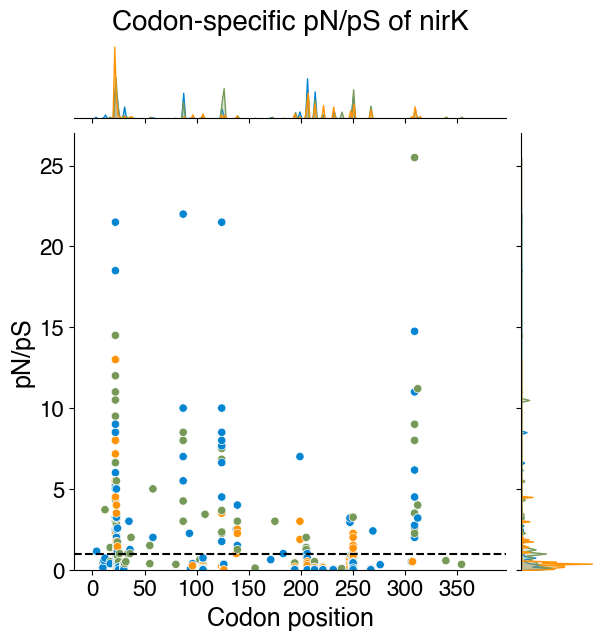

In [68]:
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 140564],x='codon_order_in_gene',y='pN/pS',hue='pH',palette=pH_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nirK',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

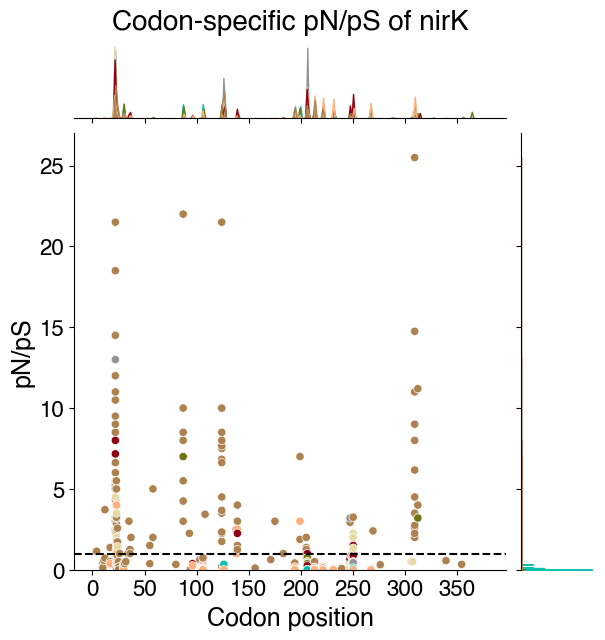

In [69]:
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 140564],x='codon_order_in_gene',y='pN/pS',hue='C source',palette=c_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nirK',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

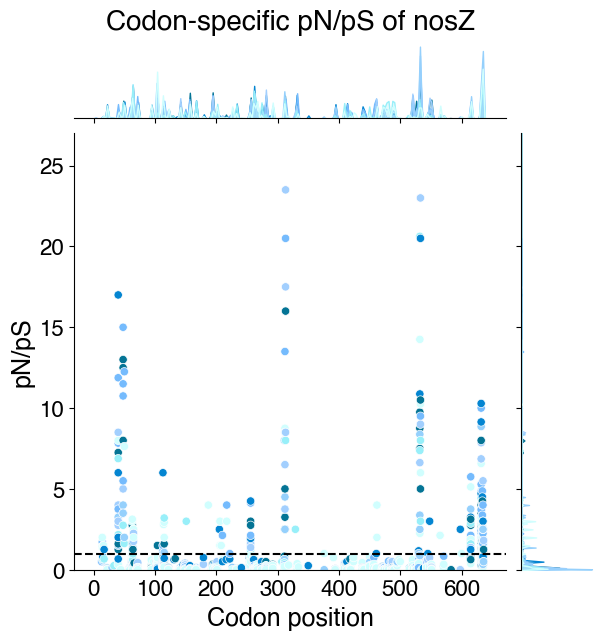

In [70]:
#Check for NosZ
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 32806],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nosZ',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

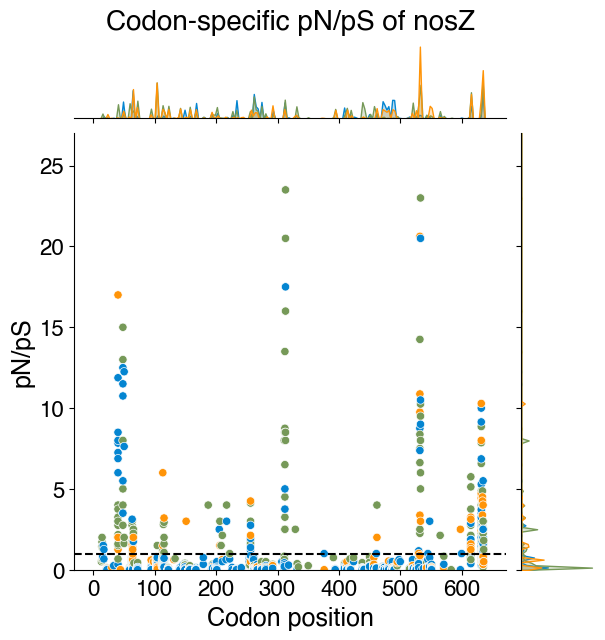

In [71]:
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 32806],x='codon_order_in_gene',y='pN/pS',hue='pH',palette=pH_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nosZ',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.show()

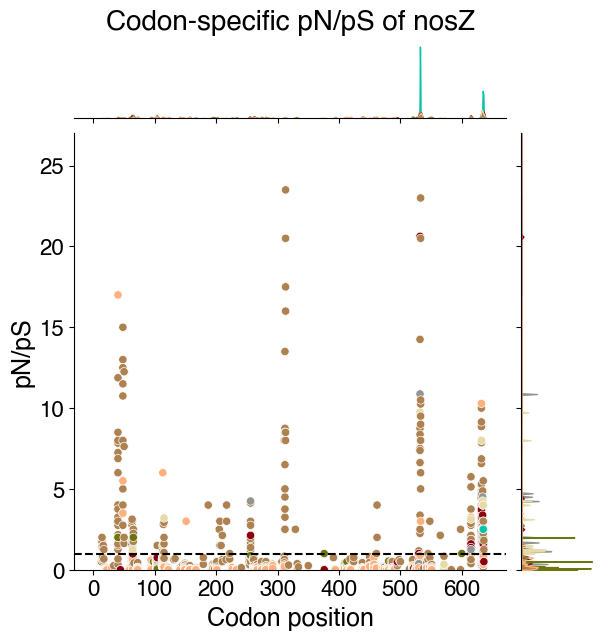

In [72]:
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 32806],x='codon_order_in_gene',y='pN/pS',hue='C source',palette=c_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of nosZ',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.show()

In [73]:
#Let's look at nitrate transporters as well real quick
bin_1_gene_calls_df[bin_1_gene_calls_df['COG20_FUNCTION'].fillna('Unknown').str.contains('NarK')]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
2220,93351,contig_11,164686,165952,r,Signature modules; Module set; Metabolic capacity,M00615,Nitrate assimilation,M00615,Inorganic ion transport and metabolism,P,"MFS transporter, NNP family, nitrate/nitrite t...",K02575,NaN,NaN,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko02000,Nitrate/nitrite transporter NarK (NarK) (PDB:4...,COG2223,ATGTCTGTACTTGAGAAAACGCAGCCCATGTCCGCCGGCGAACCAG...
3098,138225,contig_3,555010,556246,f,NaN,NaN,NaN,NaN,Inorganic ion transport and metabolism,P,NaN,NaN,NaN,NaN,NaN,NaN,Nitrate/nitrite transporter NarK (NarK) (PDB:4...,COG2223,GTGAGAGGGACGGGTGTCGAAGAGTTCCGGGATGGGTGGCGGCTCG...


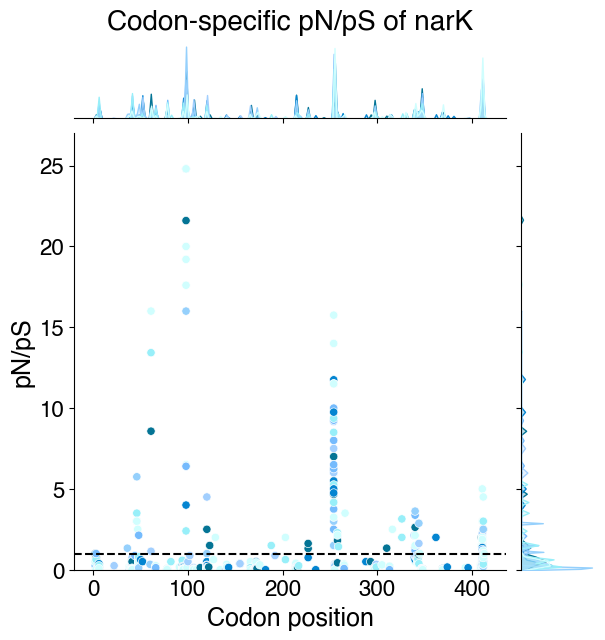

In [74]:
#Check for NarK
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 93351],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of narK',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

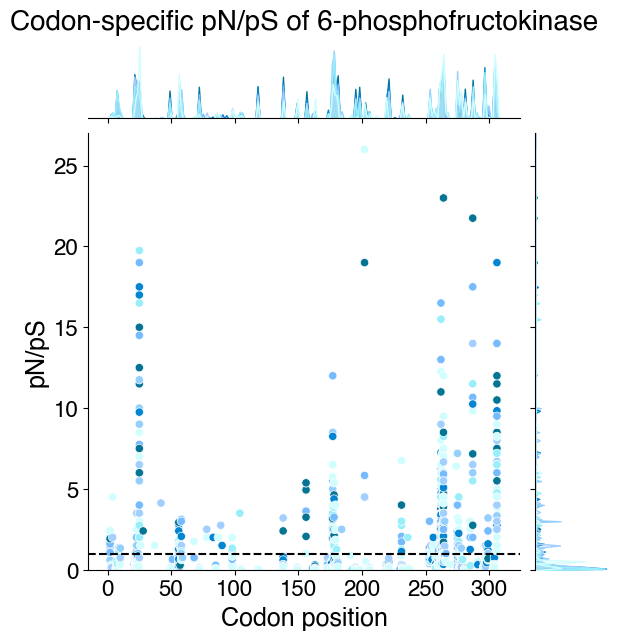

In [75]:
#Check out some other central carbon metabolism genes
g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 137852],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of 6-phosphofructokinase',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.show()

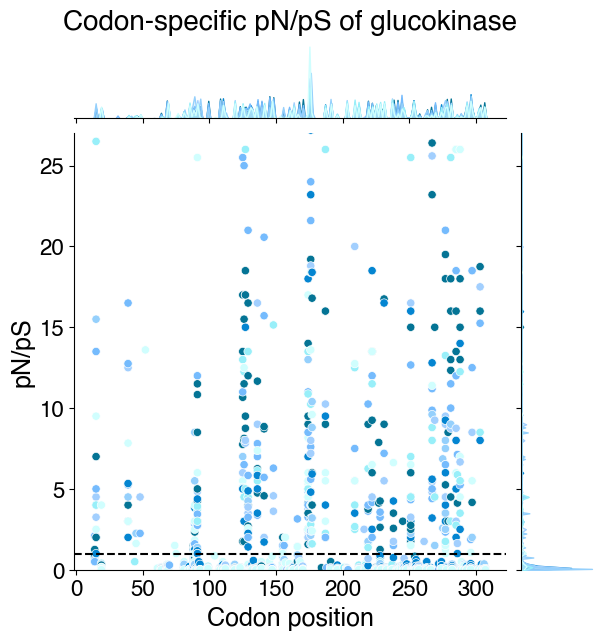

In [76]:

g = sns.jointplot(bin_1_var_info_df[bin_1_var_info_df['corresponding_gene_call'] == 32880],x='codon_order_in_gene',y='pN/pS',hue='[NO3]',palette=no3_palette,legend=False,
                  height=6,marginal_kws=dict(bw_adjust=0.01,common_norm=False))
plt.axhline(1,color='black',linestyle='--')
plt.ylim(0,27)

plt.title('Codon-specific pN/pS of glucokinase',fontsize=20,pad=75)
plt.ylabel('pN/pS',fontsize=18)
plt.xlabel('Codon position',fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

I stared at this codon level data and ran various statistical tests for a long time. Nothing really jumps out at any pH, NO3- concentration, or for any specific C source. The stats are inconclusive when running pairwise t-tests for every codon across pH or NO3. You'll get some significant values, but there are so many comparisons to run that's hard to trust. Even with just an eye, you see that the main finding is that mutations appear to occur in consistent locations, but not with as much specific influence from what that condition is. Not to say that wouldn't happen if a condition really selected for a specific mutation, we just don't see that here. Rather, we are most likely observing the naturally occurring variants that were found to some degree in the source population and that are located at positions that aren't extremely impactful on the function. This is still interesting and gives us targets that we could explore more deeply in the future.